# Register Bias in LLM Judges (Egyptian Arabic, Franco, code-switching) — everything in ONE notebook

## How to run (3 steps)
1. **Runtime → Change runtime type → T4 GPU → Save.**
2. **Runtime → Run all.**
3. While it runs, it may ask you for 3 things (only once each): **(a)** allow Google Drive (optional backup), **(b)** your Hugging Face token, **(c)** your Gemini API key. If you saved them in Colab *Secrets* (`HF_TOKEN`, `GEMINI_API_KEY`) it will not ask.

It takes about **1.5 to 2 hours**. If it stops or the session disconnects, just run **Run all** again: everything already finished is cached or restored from your Drive backup, so nothing is repeated.

## What is inside
| Part | What it does |
|---|---|
| 1 | Builds the dataset: 30 questions x 3 quality levels x 4 registers, and the files for the human annotators |
| 2 | Baselines: 3 text-embedding models + BERTScore with 3 contextual encoders |
| 3 | Baselines: 2 LLM judges (Qwen3-8B, Llama-3.1-8B, 4-bit) |
| 4 | Proposed method: LoRA judge trained to be register-invariant (+ ablation) |
| 5 | Limitation experiment: register-bias numbers, tables and figures |

**Human annotation.** The annotators need time, so Parts 2–5 run first with a *provisional* ground truth (the quality level). Part 5 prints this clearly. After the annotators return their files, upload them and run the last cell of Part 1, then re-run Part 5.

In [13]:
# ---- SETUP: working folder, optional Google Drive backup -----------------------------------------------
import os, sys, shutil
from pathlib import Path

WORK = (Path("/content/register_bias_judge") if Path("/content").exists() else Path("register_bias_judge")).resolve()
(WORK / "src").mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
sys.path.insert(0, str(WORK))
Path("data").mkdir(exist_ok=True); Path("results").mkdir(exist_ok=True)

USE_DRIVE = True          # keep a copy of data/ and results/ in your Google Drive (set False to skip)
BACKUP = Path("/content/drive/MyDrive/register_bias_backup")

def _drive_ok():
    try:
        from google.colab import drive
        if not Path("/content/drive/MyDrive").exists():
            drive.mount("/content/drive")
        return Path("/content/drive/MyDrive").exists()
    except Exception:
        return False

def backup():
    """Copy data/ and results/ to Drive. Called at the end of every part."""
    if USE_DRIVE and _drive_ok():
        for d in ("data", "results"):
            if Path(d).exists():
                shutil.copytree(d, BACKUP / d, dirs_exist_ok=True)
        print("backup saved to Google Drive:", BACKUP)

if USE_DRIVE and _drive_ok():                              # restore after a disconnected session
    for d in ("data", "results"):
        if (BACKUP / d).exists():
            shutil.copytree(BACKUP / d, d, dirs_exist_ok=True)
            print(f"restored {d}/ from your Drive backup")
if Path("/content/data/llm_cache.jsonl").exists() and not Path("data/llm_cache.jsonl").exists():
    shutil.copytree("/content/data", "data", dirs_exist_ok=True)      # reuse answers from your earlier notebook-01 run
    print("reused data/ from your earlier notebook-01 run")
print("working folder:", os.getcwd())

restored data/ from your Drive backup
restored results/ from your Drive backup
working folder: /content/register_bias_judge


### Helper code
The next 5 cells write the helper modules (`src/*.py`) used by Parts 2–5. They contain the evaluation functions, the register-bias statistics and the LoRA training loop. You do not need to read them; just run them.

In [14]:
%%writefile src/__init__.py
# package marker

Overwriting src/__init__.py


In [15]:
%%writefile src/common.py
"""Shared utilities for the Register-Invariant LLM Judge project.

Light dependencies only (numpy / pandas / scipy), so this module imports instantly and is fully unit-testable.
Everything that needs torch lives in src/models.py and src/lora.py.
"""
from __future__ import annotations

import random
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

# --------------------------------------------------------------------------- paths / constants
SEED = 42
ROOT = Path(__file__).resolve().parent.parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGS = RESULTS / "figures"
for _p in (DATA, RESULTS, FIGS):
    _p.mkdir(parents=True, exist_ok=True)

LEVELS = ["correct", "partial", "incorrect"]
REGISTERS = ["msa", "egyptian", "franco", "codeswitch"]
REG_LABEL = {"msa": "MSA", "egyptian": "Egyptian", "franco": "Franco", "codeswitch": "Code-switch"}
# Provisional ground truth used ONLY until human ratings exist (data/human_ratings.csv).
LEVEL_PROXY = {"correct": 5.0, "partial": 3.0, "incorrect": 1.0}


def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


# --------------------------------------------------------------------------- text helpers
_AR = re.compile(r"[\u0600-\u06FF]")
_LATIN_WORD = re.compile(r"[A-Za-z]{2,}")


def arabic_ratio(s: str) -> float:
    letters = [c for c in s if c.isalpha()]
    return sum(bool(_AR.match(c)) for c in letters) / max(len(letters), 1)


def digits_of(s: str) -> list[str]:
    s = s.translate(str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789"))
    return sorted(re.findall(r"\d+", s))


def rule_check(register: str, text: str, egyptian_source: str) -> bool:
    """Cheap sanity rules that a rewrite really is in the intended register (same rules as Part 1)."""
    if register == "egyptian":
        return arabic_ratio(text) >= 0.8
    if register == "msa":
        return arabic_ratio(text) >= 0.9 and digits_of(text) == digits_of(egyptian_source)
    if register == "franco":            # digits double as letters in Franco, so no digit check
        return not _AR.search(text) and bool(_LATIN_WORD.search(text))
    if register == "codeswitch":
        return bool(_AR.search(text)) and bool(_LATIN_WORD.search(text)) and digits_of(text) == digits_of(egyptian_source)
    raise ValueError(register)


# --------------------------------------------------------------------------- data loading
def load_items(only_selected: bool = True, verbose: bool = True) -> pd.DataFrame:
    """Candidate answers (one row per question x level x register) + ground truth.

    * applies the annotators' corrections from data/equivalence_check_done.csv if that file exists;
    * adds `gold` = mean human rating if data/human_ratings.csv exists, else a provisional proxy
      from the quality level. `gold_source` says which one was used (report it!).
    """
    cand = pd.read_csv(DATA / "candidates_long.csv")
    if only_selected:
        cand = cand[cand.status == "selected"].copy()

    eq_path = DATA / "equivalence_check_done.csv"
    n_fixed = n_flagged = 0
    cand["equiv_flagged"] = False
    if eq_path.exists():
        eq = pd.read_csv(eq_path).fillna("")
        fix = eq[eq.corrected_answer.astype(str).str.strip() != ""].set_index("item_id").corrected_answer
        mask = cand.item_id.isin(fix.index)
        cand.loc[mask, "answer"] = cand.loc[mask, "item_id"].map(fix)
        n_fixed = int(mask.sum())
        bad = set(eq[eq.human_same_meaning.astype(str).str.lower().isin(["n", "no", "0", "false"])].item_id) - set(fix.index)
        cand["equiv_flagged"] = cand.item_id.isin(bad)
        n_flagged = int(cand.equiv_flagged.sum())

    hr_path = DATA / "human_ratings.csv"
    if hr_path.exists():
        hr = pd.read_csv(hr_path)[["item_id", "human_mean"]]
        cand = cand.merge(hr, on="item_id", how="left")
    else:
        cand["human_mean"] = np.nan
    proxy = cand.level.map(LEVEL_PROXY)
    cand["gold"] = cand.human_mean.fillna(proxy)
    cand["gold_source"] = np.where(cand.human_mean.notna(), "human", "proxy")

    if verbose:
        print(f"items: {len(cand)} | questions: {cand.question_id.nunique()} | "
              f"gold from human ratings: {(cand.gold_source == 'human').sum()} / {len(cand)} "
              f"(rest = provisional level proxy) | corrections applied: {n_fixed} | flagged non-equivalent: {n_flagged}")
    return cand.reset_index(drop=True)


def build_pairs(items: pd.DataFrame, ref_registers=("egyptian", "msa")) -> pd.DataFrame:
    """(question, reference, candidate) rows for every evaluator.

    The reference is the *correct* answer of the same question written in `ref_register`.
    Using two reference registers separates plain register *mismatch* with the reference from real bias.
    """
    correct = items[items.level == "correct"]
    ref_tbl = correct.pivot(index="question_id", columns="register", values="answer")
    parts = []
    for rr in ref_registers:
        d = items.copy()
        d["ref_register"] = rr
        d["reference"] = d.question_id.map(ref_tbl[rr])
        parts.append(d)
    pairs = pd.concat(parts, ignore_index=True)
    assert pairs.reference.notna().all(), "missing reference answers (check candidates_long.csv)"
    pairs["pair_id"] = pairs.item_id + "|ref=" + pairs.ref_register
    pairs = pairs.rename(columns={"answer": "candidate"})
    cols = ["pair_id", "item_id", "question_id", "level", "register", "ref_register",
            "question", "reference", "candidate", "gold", "gold_source"]
    return pairs[cols].reset_index(drop=True)


def save_scores(df: pd.DataFrame, family: str) -> Path:
    """df columns: pair_id, evaluator, score (+ optional family). Stored as results/scores_<family>.csv.
    MERGES with an existing file (rows of the same evaluators are replaced), so a re-run never loses finished work."""
    out = df.copy()
    if "family" not in out.columns:          # callers may set a finer family per evaluator
        out["family"] = family
    path = RESULTS / f"scores_{family}.csv"
    if path.exists():
        old = pd.read_csv(path)
        out = pd.concat([old[~old.evaluator.isin(out.evaluator.unique())], out], ignore_index=True)
    out.to_csv(path, index=False)
    return path


def done_evaluators(family: str) -> set:
    """Evaluators already scored in results/scores_<family>.csv (used to resume after a crash)."""
    path = RESULTS / f"scores_{family}.csv"
    return set(pd.read_csv(path).evaluator) if path.exists() else set()


def load_scores() -> pd.DataFrame:
    files = sorted(RESULTS.glob("scores_*.csv"))
    if not files:
        raise FileNotFoundError("no results/scores_*.csv yet: run Parts 2, 3 and 4 first")
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True)


# --------------------------------------------------------------------------- LLM-judge prompts
RUBRIC_PLAIN = (
    "Rate how well the candidate answer answers the question, compared with the reference answer, on a 1-5 scale:\n"
    "5 = fully correct and complete\n"
    "4 = correct, with a minor omission\n"
    "3 = partially correct (key information missing, nothing false)\n"
    "2 = mostly wrong, with a trace of correct information\n"
    "1 = wrong or irrelevant"
)
REGISTER_AGNOSTIC_NOTE = (
    "Judge ONLY the information content. The candidate may be written in Modern Standard Arabic, Egyptian Arabic, "
    "Franco-Arabic (Arabic in Latin letters), or mixed with English. Dialect, script, spelling and style must NOT "
    "change the score: two answers that carry the same information must get the same score."
)
JUDGE_VARIANTS = ("plain", "agnostic")


def judge_messages(question: str, reference: str, candidate: str, variant: str = "plain") -> list[dict]:
    """One single user message (works with every chat template, including ones without a system role)."""
    if variant not in JUDGE_VARIANTS:
        raise ValueError(variant)
    note = ("\n\n" + REGISTER_AGNOSTIC_NOTE) if variant == "agnostic" else ""
    text = (
        f"You are a strict grader of answers to questions.\n\n"
        f"Question: {question}\n\nReference answer: {reference}\n\nCandidate answer: {candidate}\n\n"
        f"{RUBRIC_PLAIN}{note}\n\nRespond with a single digit from 1 to 5 and nothing else."
    )
    return [{"role": "user", "content": text}]


# --------------------------------------------------------------------------- register-bias statistics
def holm(pvals) -> np.ndarray:
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    m = len(p)
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj


def _quality_gap(g: pd.DataFrame) -> float:
    """mean score of correct answers - mean score of incorrect answers (the evaluator's own 'yardstick')."""
    c = g.loc[g.level == "correct", "score"].mean()
    i = g.loc[g.level == "incorrect", "score"].mean()
    return float(c - i)


def quality_gaps(df: pd.DataFrame) -> pd.DataFrame:
    rows = [{"evaluator": ev, "ref_register": rr, "quality_gap": _quality_gap(g)}
            for (ev, rr), g in df.groupby(["evaluator", "ref_register"])]
    return pd.DataFrame(rows)


def pairwise_register_gaps(df: pd.DataFrame, level: str = "correct", n_boot: int = 10000, seed: int = SEED) -> pd.DataFrame:
    """Paired comparison of every register pair on the SAME questions (default: correct answers only,
    where all registers carry identical information, so any difference is register bias).

    gap = score(a) - score(b). `norm_gap` = gap / quality_gap: how big the register effect is compared with the
    difference between a correct and an incorrect answer for that same evaluator (comparable across scales).
    """
    rng = np.random.default_rng(seed)
    qg = quality_gaps(df).set_index(["evaluator", "ref_register"]).quality_gap
    out = []
    for (ev, rr), g in df[df.level == level].groupby(["evaluator", "ref_register"]):
        wide = g.pivot(index="question_id", columns="register", values="score")
        rows = []
        for i, a in enumerate(REGISTERS):
            for b in REGISTERS[i + 1:]:
                d = (wide[a] - wide[b]).dropna().to_numpy()
                n = len(d)
                if n < 3:
                    continue
                boot = d[rng.integers(0, n, (n_boot, n))].mean(axis=1)
                lo, hi = np.percentile(boot, [2.5, 97.5])
                sd = d.std(ddof=1)
                try:
                    p = stats.wilcoxon(d, zero_method="wilcox").pvalue if np.any(d != 0) else 1.0
                except ValueError:
                    p = 1.0
                q = qg.get((ev, rr), np.nan)
                rows.append({"evaluator": ev, "ref_register": rr, "a": a, "b": b, "n": n,
                             "gap": d.mean(), "ci_lo": lo, "ci_hi": hi,
                             "cohen_dz": d.mean() / sd if sd > 0 else 0.0,
                             "p_wilcoxon": p, "quality_gap": q,
                             # only meaningful if the evaluator ranks correct ABOVE incorrect (quality_gap > 0)
                             "norm_gap": d.mean() / q if (not np.isnan(q) and q > 0) else np.nan})
        if rows:
            padj = holm([r["p_wilcoxon"] for r in rows])
            for r, pa in zip(rows, padj):
                r["p_holm"] = pa
            out.extend(rows)
    return pd.DataFrame(out)


def gaps_vs_msa(pw: pd.DataFrame) -> pd.DataFrame:
    """Register gaps oriented as score(MSA) - score(other register): positive = the other register is penalised.
    (REGISTERS lists MSA first, so MSA is always column `a` in pairwise_register_gaps.)"""
    return pw[pw.a == "msa"].rename(columns={"b": "other"}).drop(columns=["a"]).reset_index(drop=True)


def friedman_by_register(df: pd.DataFrame, level: str = "correct") -> pd.DataFrame:
    """Omnibus test: do the 4 registers differ at all? (Friedman, paired by question)."""
    rows = []
    for (ev, rr), g in df[df.level == level].groupby(["evaluator", "ref_register"]):
        wide = g.pivot(index="question_id", columns="register", values="score").dropna()
        if len(wide) < 3 or (wide.std(axis=1) == 0).all():      # no variation across registers at all
            p, chi = 1.0, 0.0
        else:
            chi, p = stats.friedmanchisquare(*[wide[r] for r in REGISTERS])
        rows.append({"evaluator": ev, "ref_register": rr, "friedman_chi2": chi, "friedman_p": p, "n": len(wide)})
    return pd.DataFrame(rows)


def inconsistency(df: pd.DataFrame, level: str = "correct") -> pd.DataFrame:
    """Mean per-question std of the score across the 4 registers (0 = perfectly register-invariant)."""
    qg = quality_gaps(df).set_index(["evaluator", "ref_register"]).quality_gap
    rows = []
    for (ev, rr), g in df[df.level == level].groupby(["evaluator", "ref_register"]):
        wide = g.pivot(index="question_id", columns="register", values="score").dropna()
        s = wide.std(axis=1, ddof=1).mean()
        q = qg.get((ev, rr), np.nan)
        rows.append({"evaluator": ev, "ref_register": rr, "inconsistency": s,
                     "inconsistency_norm": s / q if (not np.isnan(q) and q > 0) else np.nan})
    return pd.DataFrame(rows)


def validity_table(df: pd.DataFrame) -> pd.DataFrame:
    """Spearman correlation with the ground truth (`gold`), overall and inside each register.
    A fair judge must stay accurate in EVERY register, not just on average."""
    rows = []
    for (ev, rr), g in df.groupby(["evaluator", "ref_register"]):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")           # constant scores -> NaN correlation, handled below
            row = {"evaluator": ev, "ref_register": rr, "spearman_all": stats.spearmanr(g.score, g.gold)[0]}
        for reg in REGISTERS:
            gg = g[g.register == reg]
            row[f"spearman_{reg}"] = stats.spearmanr(gg.score, gg.gold)[0] if gg.score.nunique() > 1 else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


def flip_matrix(df: pd.DataFrame, evaluator: str, ref_register: str) -> pd.DataFrame:
    """Decision-level unfairness: P(score of a CORRECT answer in register r1 < score of an INCORRECT answer
    in register r2) for the same question (ties count 0.5). Off-diagonal mass = register-induced ranking errors."""
    g = df[(df.evaluator == evaluator) & (df.ref_register == ref_register)]
    cor = g[g.level == "correct"].pivot(index="question_id", columns="register", values="score")
    inc = g[g.level == "incorrect"].pivot(index="question_id", columns="register", values="score")
    qs = cor.index.intersection(inc.index)
    m = pd.DataFrame(index=REGISTERS, columns=REGISTERS, dtype=float)
    for r1 in REGISTERS:
        for r2 in REGISTERS:
            c, i = cor.loc[qs, r1].to_numpy(), inc.loc[qs, r2].to_numpy()
            m.loc[r1, r2] = np.mean((c < i) + 0.5 * (c == i))
    m.index.name = "correct in"
    m.columns.name = "incorrect in"
    return m


def summarize(df: pd.DataFrame) -> pd.DataFrame:
    """One row per evaluator x reference register: the numbers for the report table."""
    qg = quality_gaps(df)
    pw = pairwise_register_gaps(df)
    fr = friedman_by_register(df)
    inc = inconsistency(df)
    val = validity_table(df)
    rows = []
    for _, r in qg.iterrows():
        ev, rr = r.evaluator, r.ref_register
        sub = pw[(pw.evaluator == ev) & (pw.ref_register == rr)]
        vs_msa = sub[(sub.a == "msa") | (sub.b == "msa")].copy()
        # orient every gap as score(MSA) - score(other): positive = the other register is penalised
        vs_msa["oriented"] = np.where(vs_msa.a == "msa", vs_msa.norm_gap, -vs_msa.norm_gap)
        fm = flip_matrix(df, ev, rr).to_numpy()
        same = np.mean(np.diag(fm))
        cross = np.mean(fm[~np.eye(len(REGISTERS), dtype=bool)])
        rows.append({
            "evaluator": ev, "ref_register": rr, "quality_gap": r.quality_gap,
            "max_penalty_vs_msa_norm": vs_msa.oriented.max() if len(vs_msa) else np.nan,
            "worst_gap_p_holm": sub.p_holm.min() if len(sub) else np.nan,
            "friedman_p": fr[(fr.evaluator == ev) & (fr.ref_register == rr)].friedman_p.iloc[0],
            "inconsistency_norm": inc[(inc.evaluator == ev) & (inc.ref_register == rr)].inconsistency_norm.iloc[0],
            "flip_same_register": same, "flip_cross_register": cross,
            "spearman_all": val[(val.evaluator == ev) & (val.ref_register == rr)].spearman_all.iloc[0],
        })
    return pd.DataFrame(rows)

Overwriting src/common.py


In [16]:
%%writefile src/edrac.py
"""EDRAC loading and question filtering (identical logic to Part 1, reused for the LoRA training pool)."""
from __future__ import annotations

import re

import pandas as pd

from .common import arabic_ratio

DEICTIC = re.compile(r"المتحدث|المتحدثة|الفيديو|الحلقة|المقطع|النص|الكلام ده|المذيع|الضيف|الراوي")


def norm_ar(s: str) -> str:
    s = re.sub(r"[\u064B-\u0652\u0640]", "", s)
    return s.translate(str.maketrans("أإآ", "ااا")).strip()


YESNO = {norm_ar(x) for x in ["ايوه", "أيوه", "اه", "آه", "أه", "لا", "لأ", "لاء", "نعم", "ايوة"]}


def clean_passage(p) -> str:
    p = re.sub(r"\*\*[^*]*\*\*", " ", str(p))        # drop "** 0 المتحدث **" speaker headers
    return re.sub(r"\s+", " ", p).strip()


def edrac_to_qa(raw: pd.DataFrame) -> pd.DataFrame:
    """Wide EDRAC table (Question 1..10 / Answer 1..10 per passage) -> one row per QA pair (Egyptian only)."""
    raw = raw[raw["Dialect"] == "egy"].reset_index(drop=True)
    records = []
    for _, row in raw.iterrows():
        for i in range(1, 11):
            q, a = row.get(f"Question {i}"), row.get(f"Answer {i}")
            if pd.isna(q) or pd.isna(a) or not str(q).strip() or not str(a).strip():
                continue
            records.append({"source_id": row["ID"], "passage": clean_passage(row["Passage"]),
                            "qa_index": i, "question": str(q).strip(), "answer": str(a).strip()})
    return pd.DataFrame(records)


def load_edrac_qa() -> pd.DataFrame:
    from datasets import load_dataset
    return edrac_to_qa(load_dataset("MBZUAI/EDRAC", split="test").to_pandas())


def filter_qa(qa: pd.DataFrame) -> pd.DataFrame:
    """Short factual self-contained questions with Arabic-script answers (same filter as Part 1)."""
    f = qa.copy()
    f["q_words"] = f.question.str.split().str.len()
    f["a_words"] = f.answer.str.split().str.len()
    ok = f.a_words.between(3, 25) & f.q_words.between(4, 25)
    ok &= f.answer.map(arabic_ratio) >= 0.8
    ok &= ~f.question.map(lambda q: bool(DEICTIC.search(q)))
    ok &= ~f.question.map(lambda q: norm_ar(q).startswith("هل") or " ولا " in f" {q} ")
    ok &= ~f.answer.map(lambda a: norm_ar(a).strip(" .،!؟") in YESNO)
    return f[ok].reset_index(drop=True)

Overwriting src/edrac.py


In [17]:
%%writefile src/models.py
"""torch-dependent helpers: embedding / BERTScore evaluators and the logit-based LLM judge scorer."""
from __future__ import annotations

import gc
import os

import numpy as np
import pandas as pd
import torch

from .common import judge_messages

DIGITS = [1, 2, 3, 4, 5]


def device() -> str:
    return "cuda" if torch.cuda.is_available() else "cpu"


def free_gpu() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def hf_login() -> None:
    """Hugging Face login, asked at most once: already logged in -> nothing; else $HF_TOKEN / Colab Secrets; else prompt.
    (Needed for gated models such as Llama and for EDRAC.)"""
    from huggingface_hub import get_token, login
    if get_token():
        return
    tok = os.environ.get("HF_TOKEN")
    if not tok:
        try:
            from google.colab import userdata
            tok = userdata.get("HF_TOKEN")
        except Exception:
            tok = None
    login(token=tok) if tok else login()


# ----------------------------------------------------------------------------------- embedding evaluators
def embedding_cosine(model_id: str, pairs: pd.DataFrame, prefix: str = "", batch_size: int = 32) -> np.ndarray:
    """Cosine similarity between reference and candidate under a text-embedding model."""
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer(model_id, device=device(), trust_remote_code=False)
    texts = sorted(set(pairs.reference) | set(pairs.candidate))
    emb = model.encode([prefix + t for t in texts], batch_size=batch_size, normalize_embeddings=True,
                       convert_to_numpy=True, show_progress_bar=False)
    lookup = {t: i for i, t in enumerate(texts)}
    ref = emb[[lookup[t] for t in pairs.reference]]
    cand = emb[[lookup[t] for t in pairs.candidate]]
    del model
    free_gpu()
    return (ref * cand).sum(axis=1)


# ----------------------------------------------------------------------------------- contextual-encoder evaluators
def bertscore_f1(model_type: str, num_layers: int, candidates: list[str], references: list[str],
                 batch_size: int = 32) -> np.ndarray:
    """BERTScore F1 (greedy token matching on contextual embeddings from `num_layers`), no IDF, no baseline rescaling."""
    from bert_score import BERTScorer
    scorer = BERTScorer(model_type=model_type, num_layers=num_layers, batch_size=batch_size,
                        device=device(), idf=False, rescale_with_baseline=False)
    tok = scorer._tokenizer
    if tok.model_max_length is None or tok.model_max_length > 100_000:    # some tokenizers ship "infinite" max length
        tok.model_max_length = 512
    _, _, f1 = scorer.score(candidates, references)
    del scorer
    free_gpu()
    return f1.cpu().numpy()


# ----------------------------------------------------------------------------------- LLM judge
def load_causal_lm(name: str, four_bit: bool = True):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    tok.padding_side = "left"                      # we read the logits at the last position
    kw = {}
    if four_bit:
        from transformers import BitsAndBytesConfig
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
            bnb_4bit_compute_dtype=torch.float16)
        kw["device_map"] = {"": 0}
    model = AutoModelForCausalLM.from_pretrained(name, **kw)
    if not four_bit:
        model = model.to(device())
        if torch.cuda.is_available():
            model = model.half()
    model.eval()
    return model, tok


def chat_prompt(tok, messages: list[dict]) -> str:
    """Chat-template text ending right where the assistant must answer. Qwen3's thinking mode is switched off."""
    try:
        return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    except TypeError:
        return tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)


def digit_token_ids(tok) -> list[int]:
    ids = []
    for d in DIGITS:
        t = tok.encode(str(d), add_special_tokens=False)
        if len(t) != 1:
            raise ValueError(f"'{d}' is not a single token for {tok.name_or_path!r}: {t}")
        ids.append(t[0])
    return ids


@torch.no_grad()
def digit_distribution(model, tok, prompts: list[str], batch_size: int = 8, desc: str = "") -> np.ndarray:
    """P(score = 1..5): softmax over the logits of the five digit tokens at the answer position.

    Reading probabilities instead of parsing generated text means no parsing failures, deterministic scores,
    and a continuous expected score (a 4.6 vs 4.2 difference is information, not noise)."""
    from tqdm.auto import tqdm
    ids = torch.tensor(digit_token_ids(tok), device=model.device)
    probs = np.zeros((len(prompts), len(DIGITS)), dtype=float)
    order = np.argsort([len(p) for p in prompts])            # similar lengths together -> less padding
    for s in tqdm(range(0, len(prompts), batch_size), desc=desc, leave=False):
        idx = order[s:s + batch_size]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        logits = model(**enc).logits[:, -1, :]
        probs[idx] = torch.softmax(logits[:, ids].float(), dim=-1).cpu().numpy()
    return probs


def expected_score(probs: np.ndarray) -> np.ndarray:
    return probs @ np.array(DIGITS, dtype=float)


def judge_pairs(model, tok, pairs: pd.DataFrame, variant: str = "plain", batch_size: int = 8, desc: str = ""):
    prompts = [chat_prompt(tok, judge_messages(r.question, r.reference, r.candidate, variant))
               for r in pairs.itertuples()]
    probs = digit_distribution(model, tok, prompts, batch_size=batch_size, desc=desc)
    return expected_score(probs), probs

Overwriting src/models.py


In [18]:
%%writefile src/lora.py
"""Register-invariant LoRA judge: training-data construction, training loop, evaluation helpers."""
from __future__ import annotations

import random
import re

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from .common import _AR, _LATIN_WORD, REGISTERS, SEED, arabic_ratio, judge_messages
from .models import DIGITS, chat_prompt, digit_distribution, digit_token_ids, expected_score

# ------------------------------------------------------------------------------------------ register conversion
REG_PROMPT = """Rewrite the Egyptian Arabic answer below in three other writing registers WITHOUT changing its meaning. Do not add, remove or correct anything; keep names and numbers identical.

Question (context only): <<q>>
Egyptian answer: <<a>>

Output exactly three lines and nothing else:
MSA: <Modern Standard Arabic, Arabic script>
FRANCO: <Egyptian Arabic written in Latin letters (Arabizi); digits 2 3 5 7 8 9 6 stand for ء ع خ ح غ ق ط; no Arabic script at all>
CODESWITCH: <Egyptian Arabic in Arabic script where 1-3 content words are written in English>

Example for "القاهرة عاصمة مصر":
MSA: القاهرة هي عاصمة جمهورية مصر العربية.
FRANCO: El Qahera 3asmet Masr.
CODESWITCH: Cairo هي عاصمة مصر."""

_LINE = re.compile(r"^(MSA|FRANCO|ARABIZI|CODE[\s_-]?SWITCH(?:ING)?)\s*[:\uFF1A\-\u2013\u2014]\s*(.+)$", re.I)
_AR_PUNCT = str.maketrans("", "", "\u060C\u061B\u061F")        # Arabic comma, semicolon, question mark


def parse_register_output(text: str) -> dict:
    """Tolerant parser -> {"msa","franco","codeswitch"} with whichever lines were found (possibly none).

    Accepts bullets, numbering, markdown bold (**MSA:**), 'Arabizi' for Franco, 'Code-switching', quotes and <...>.
    If the model echoes the example first, the LAST occurrence of each line (its own answer) wins."""
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S)
    out = {}
    for line in text.splitlines():
        line = line.strip().replace("**", "").replace("__", "")
        line = re.sub(r"^[\s>*\-\u2022#]+", "", line)
        line = re.sub(r"^\d+[.)]\s*", "", line)
        m = _LINE.match(line)
        if not m:
            continue
        k = m.group(1).lower()
        key = "msa" if k == "msa" else "franco" if k in ("franco", "arabizi") else "codeswitch"
        val = m.group(2).strip().strip('"\u201c\u201d\u00ab\u00bb').strip()
        val = re.sub(r"^<(.*)>$", r"\1", val).strip()
        if val:
            out[key] = val
    return out


def valid_register(reg: str, text: str) -> bool:
    """Rules for MACHINE-GENERATED TRAINING data only (the benchmark uses the stricter rule_check in common.py)."""
    if reg == "msa":
        return arabic_ratio(text) >= 0.8
    if reg == "franco":                                    # Arabic punctuation marks are tolerated, Arabic letters are not
        t = text.translate(_AR_PUNCT)
        return not _AR.search(t) and bool(_LATIN_WORD.search(t))
    if reg == "codeswitch":
        return bool(_AR.search(text)) and bool(_LATIN_WORD.search(text))
    raise ValueError(reg)


def validate_conversion(answer: str, conv: dict | None) -> dict:
    """Keep every register that parsed and passed its rule. Always contains "egyptian" (the original answer)."""
    out = {"egyptian": answer}
    for reg in ("msa", "franco", "codeswitch"):
        t = (conv or {}).get(reg)
        if t and valid_register(reg, t):
            out[reg] = t
    return out


def conversion_failures(answer: str, conv: dict | None) -> list[str]:
    """Why registers were dropped: 'missing:<reg>' (not in the model output) or 'rule:<reg>' (present but rejected)."""
    why = []
    for reg in ("msa", "franco", "codeswitch"):
        t = (conv or {}).get(reg)
        if not t:
            why.append(f"missing:{reg}")
        elif not valid_register(reg, t):
            why.append(f"rule:{reg}")
    return why


@torch.no_grad()
def generate_register_texts(model, tok, jobs: list[tuple[str, str]], batch_size: int = 8,
                            max_new_tokens: int = 320, desc: str = "convert") -> list[str]:
    """jobs = [(question, egyptian_answer)] -> RAW model text per job (greedy decoding, deterministic).
    Raw text is returned (not parsed) so it can be cached and re-parsed for free when the parser improves."""
    from tqdm.auto import tqdm
    outs: list[str] = [""] * len(jobs)
    prompts = [chat_prompt(tok, [{"role": "user", "content": REG_PROMPT.replace("<<q>>", q).replace("<<a>>", a)}])
               for q, a in jobs]
    order = np.argsort([len(p) for p in prompts])
    for s in tqdm(range(0, len(prompts), batch_size), desc=desc, leave=False):
        idx = order[s:s + batch_size]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        texts = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
        for i, t in zip(idx, texts):
            outs[i] = t
    return outs


# ------------------------------------------------------------------------------------------ training data
def _jaccard(a: str, b: str) -> float:
    A, B = set(a.split()), set(b.split())
    return len(A & B) / max(len(A | B), 1)


def select_train_questions(pool: pd.DataFrame, excluded_sources, max_per_passage: int = 3,
                           val_frac: float = 0.2, seed: int = SEED, min_questions: int = 40) -> pd.DataFrame:
    """Passage-disjoint training/validation questions with a hard negative each.

    * passages used by the benchmark (test + reserve) are excluded -> no leakage;
    * the hard negative of a question is the answer to ANOTHER question of the same passage: same topic and
      style, but wrong for this question (no LLM needed, so it is free and reproducible);
    * train/val are split by passage."""
    rng = random.Random(seed)
    pool = pool[~pool.source_id.isin(set(excluded_sources))]
    counts = pool.groupby("source_id").size()
    passages = sorted(counts[counts >= 2].index)
    rng.shuffle(passages)
    n_val = max(1, round(val_frac * len(passages))) if len(passages) > 1 else 0
    val_set = set(passages[:n_val])
    rows = []
    for pid in passages:
        g = pool[pool.source_id == pid].reset_index(drop=True)
        take = g.sample(n=min(max_per_passage, len(g)), random_state=seed)
        for _, r in take.iterrows():
            cands = sorted({(a, q) for a, q in zip(g.answer, g.question) if a != r.answer and _jaccard(a, r.answer) <= 0.5})
            if not cands:
                continue
            neg_a, neg_q = rng.choice(cands)
            rows.append({"source_id": pid, "question": r.question, "answer": r.answer, "neg_answer": neg_a,
                         "neg_question": neg_q, "split": "val" if pid in val_set else "train"})
    if len(rows) < min_questions:
        # Scarce data: also use passages that have a single qualifying pair; the negative then comes from ANOTHER
        # training passage (easier than a same-passage negative, but better than too little data).
        used = {r["source_id"] for r in rows}
        donors = pool[~pool.source_id.isin(val_set)]
        for pid, g in pool[~pool.source_id.isin(used)].groupby("source_id"):
            r = g.iloc[0]
            cands = sorted({(a, q) for a, q, p in zip(donors.answer, donors.question, donors.source_id)
                            if p != pid and _jaccard(a, r.answer) <= 0.5})
            if not cands:
                continue
            neg_a, neg_q = rng.choice(cands)
            rows.append({"source_id": pid, "question": r.question, "answer": r.answer, "neg_answer": neg_a,
                         "neg_question": neg_q, "split": "train"})
    return pd.DataFrame(rows)


def build_groups(sel: pd.DataFrame, converted: dict, seed: int = SEED, min_regs: int = 3) -> list[dict]:
    """A *group* = the same content in several registers: 1 label, up to 4 candidate texts.
    correct group  -> candidates = the gold answer in every available register, label 5
    incorrect group-> candidates = the hard negative in every available register, label 1
    The reference is the gold answer in a random register (Egyptian or MSA), like the test protocol.
    A group needs at least `min_regs` registers (Egyptian counts), otherwise its consistency signal is too weak."""
    rng = random.Random(seed)
    groups = []
    for r in sel.itertuples():
        gold, neg = converted.get(r.answer), converted.get(r.neg_answer)
        if not gold or not neg or len(gold) < min_regs or len(neg) < min_regs:
            continue
        ref_reg = rng.choice([x for x in ("egyptian", "msa") if x in gold])
        for quality, label, src in (("correct", 5, gold), ("incorrect", 1, neg)):
            groups.append({"split": r.split, "source_id": r.source_id, "question": r.question,
                           "reference": gold[ref_reg], "ref_register": ref_reg, "quality": quality,
                           "label": label, "candidates": {reg: src[reg] for reg in REGISTERS if reg in src}})
    return groups


def group_prompts(tok, group: dict, regs) -> list[str]:
    return [chat_prompt(tok, judge_messages(group["question"], group["reference"], group["candidates"][r], "plain"))
            for r in regs if r in group["candidates"]]


# ------------------------------------------------------------------------------------------ training
def train_lora_judge(model, tok, groups: list[dict], regs, steps: int = 120, groups_per_step: int = 2,
                     lr: float = 2e-4, lam: float = 0.0, seed: int = SEED, r: int = 16, alpha: int = 32,
                     dropout: float = 0.05, warmup: float = 0.1, log_every: int = 10):
    """LoRA fine-tuning of the judge on the 5-way digit distribution (the same readout used at inference).

    loss = CE(score digit)  +  lam * mean_over_groups Var_registers(expected score)
    The second term is the register-consistency penalty: the SAME content written in different registers must
    receive the SAME score. lam = 0 gives plain LoRA. `regs` decides which registers the model may see
    (["egyptian"] = no register augmentation)."""
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training

    torch.manual_seed(seed)
    rng = random.Random(seed)
    if getattr(model, "is_loaded_in_4bit", False):
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout, task_type="CAUSAL_LM",
                     target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    model = get_peft_model(model, cfg)
    model.config.use_cache = False
    model.train()

    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    n_warm = max(1, int(warmup * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / n_warm if s < n_warm else max(0.0, (steps - s) / max(1, steps - n_warm)))
    use_amp = torch.cuda.is_available()
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ids = torch.tensor(digit_token_ids(tok), device=model.device)
    digits = torch.tensor(DIGITS, dtype=torch.float32, device=model.device)

    queue: list[int] = []
    log = []
    for step in range(steps):
        while len(queue) < groups_per_step:
            queue.extend(rng.sample(range(len(groups)), len(groups)))
        batch = [groups[queue.pop(0)] for _ in range(groups_per_step)]
        prompts, labels, gid = [], [], []
        for k, g in enumerate(batch):
            ps = group_prompts(tok, g, regs)
            prompts += ps
            labels += [g["label"] - 1] * len(ps)
            gid += [k] * len(ps)
        enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        with torch.autocast(device_type="cuda" if use_amp else "cpu", dtype=torch.float16 if use_amp else torch.bfloat16,
                            enabled=use_amp):
            logits = model(**enc).logits[:, -1, :]
        logp = F.log_softmax(logits[:, ids].float(), dim=-1)
        y = torch.tensor(labels, device=logp.device)
        ce = F.nll_loss(logp, y)
        exp = (logp.exp() * digits).sum(-1)
        gid_t = torch.tensor(gid, device=logp.device)
        cons = torch.zeros((), device=logp.device)
        multi = [k for k in range(len(batch)) if (gid_t == k).sum() > 1]
        if multi:
            cons = torch.stack([exp[gid_t == k].var(unbiased=False) for k in multi]).mean()
        loss = ce + lam * cons
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        opt.zero_grad(set_to_none=True)
        log.append({"step": step + 1, "loss": loss.item(), "ce": ce.item(), "cons": float(cons)})
        if (step + 1) % log_every == 0:
            w = pd.DataFrame(log[-log_every:]).mean()
            print(f"step {step + 1}/{steps} | loss {w.loss:.3f} | ce {w.ce:.3f} | consistency {w.cons:.3f}")
    model.eval()
    model.config.use_cache = True
    return model, pd.DataFrame(log)


@torch.no_grad()
def evaluate_groups(model, tok, groups: list[dict], batch_size: int = 8) -> pd.DataFrame:
    """Expected judge score for every (group, register): used for the validation sanity check."""
    rows, prompts = [], []
    for gi, g in enumerate(groups):
        for reg in [r for r in REGISTERS if r in g["candidates"]]:
            prompts.append(chat_prompt(tok, judge_messages(g["question"], g["reference"], g["candidates"][reg], "plain")))
            rows.append({"group": gi, "quality": g["quality"], "label": g["label"], "register": reg})
    sc = expected_score(digit_distribution(model, tok, prompts, batch_size=batch_size, desc="val"))
    out = pd.DataFrame(rows)
    out["score"] = sc
    return out

Overwriting src/lora.py


In [19]:
%pip install -q "transformers>=4.51" accelerate bitsandbytes peft sentence-transformers bert-score datasets google-genai openai scikit-learn scipy tqdm matplotlib

# Part 1 — Dataset Creation (Register Bias in Arabic LLM-as-Judge)

**الهدف:** من EDRAC (Egyptian فقط) نطلّع benchmark فيه 30 سؤال، ولكل سؤال 3 مستويات جودة × 4 registers.

| Level | Meaning | Required? |
|---|---|---|
| `correct` | الإجابة الذهبية من EDRAC | نعم (120 item) |
| `partial` | جزء صح، ناقص عنصر أساسي | extension |
| `incorrect` | سليمة لغويًا لكن غلط في المحتوى | extension |

**Pipeline:** فلترة الأسئلة ← توليد partial/incorrect بالمصري ← تحويل كل إجابة لـ MSA / Franco / Code-switching ← تحقق تلقائي من التكافؤ ← ملفات الـ annotation.

**مبدأ التصميم:** كل الـ registers بتتولّد من *نفس* الإجابة المصرية، فالغلط (في partial/incorrect) بيتنقل زي ما هو، والفرق الوحيد هو طريقة الكتابة.

**قبل التشغيل:** شغّلي الـ cells بالترتيب من فوق. المفتاح بيتقرا من Colab Secrets (`GEMINI_API_KEY`) أو بيتطلب منك مرة واحدة في الـ cell الخاصة بالاختبار. مفيش cells ترقيع.

In [20]:
import os, re, json, hashlib, random, time
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ------------------------- Config -------------------------
SEED = 42
PROVIDER = "gemini"                # "gemini" or "openai"
GEN_MODEL = "gemini-3.8-flash"     # writes partial/incorrect + register rewrites
CHECK_MODEL = "gemini-3.7-flash"   # equivalence checker: a DIFFERENT model than GEN_MODEL on purpose
FALLBACK_MODELS = ["gemini-3.6-flash", "gemini-3.5-flash", "gemini-flash-latest", "gemini-3.5-flash-lite"]   # tried in order if a model is busy or out of quota; [] disables
MAX_RPM = 8                        # client-side cap on requests per minute (lower it to 4-5 if you still see 429)
N_QUESTIONS = 30
N_RESERVE = 6                      # extra questions in case some are dropped after manual review
ANNOTATE_LEVELS = ["correct", "partial", "incorrect"]   # use ["correct", "incorrect"] if time is short
DATA = Path("data"); DATA.mkdir(exist_ok=True)
CACHE_PATH = DATA / "llm_cache.jsonl"

random.seed(SEED); np.random.seed(SEED)

def get_key(name):
    # order: environment -> Colab Secrets -> ask once (hidden input). No separate "fix" cell needed.
    key = os.environ.get(name)
    if not key:
        try:
            from google.colab import userdata
            key = userdata.get(name)
        except Exception:
            key = None
    if not key:
        import getpass
        key = getpass.getpass(f"{name}: ")
    os.environ[name] = key
    return key

In [21]:
# ------------------- LLM wrapper (cached + retried) -------------------
# Every response is cached in data/llm_cache.jsonl, so re-running the notebook is free,
# survives Colab disconnects, and gives identical outputs (reproducibility).

def parse_json(text, required=()):
    # required: tuple of keys, or dict {key: (subkeys...)} to also validate nested keys
    text = text.strip()
    text = re.sub(r"^```(?:json)?\s*|\s*```$", "", text).strip()
    obj = json.loads(text)
    for k in required:
        if k not in obj:
            raise ValueError(f"missing key: {k}")
        subs = required[k] if isinstance(required, dict) else ()
        for sk in subs:
            if not isinstance(obj[k], dict) or sk not in obj[k]:
                raise ValueError(f"missing key: {k}.{sk}")
    return obj

_cache = {}
if CACHE_PATH.exists():
    for line in CACHE_PATH.read_text(encoding="utf-8").splitlines():
        if line.strip():
            r = json.loads(line); _cache[r["key"]] = r["text"]

_clients = {}
def _client():
    if PROVIDER not in _clients:
        if PROVIDER == "gemini":
            from google import genai
            _clients[PROVIDER] = genai.Client(api_key=get_key("GEMINI_API_KEY"))
        else:
            from openai import OpenAI
            _clients[PROVIDER] = OpenAI(api_key=get_key("OPENAI_API_KEY"))
    return _clients[PROVIDER]

def _raw_call(prompt, model, temperature):
    c = _client()
    if PROVIDER == "gemini":
        from google.genai import types
        r = c.models.generate_content(
            model=model, contents=prompt,
            config=types.GenerateContentConfig(temperature=temperature,
                                               response_mime_type="application/json"))
        return r.text
    r = c.chat.completions.create(
        model=model, temperature=temperature,
        response_format={"type": "json_object"},
        messages=[{"role": "user", "content": prompt}])
    return r.choices[0].message.content

_FATAL = ("API key", "NOT_FOUND", "PERMISSION_DENIED", "UNAUTHENTICATED", "no longer available", "INVALID_ARGUMENT")
_TRANSIENT = ("429", "500", "502", "503", "504", "RESOURCE_EXHAUSTED", "UNAVAILABLE", "DEADLINE_EXCEEDED",
              "overloaded", "high demand")
_down_until = {}     # model -> timestamp; a model that just failed is skipped for a while (circuit breaker)
USAGE = {}           # model -> number of responses used (report this in the paper if a fallback was needed)
_last_call = [0.0]

def _throttle():
    # stay under the free-tier requests-per-minute limit
    wait = _last_call[0] + 60.0 / MAX_RPM - time.time()
    if wait > 0:
        time.sleep(wait)
    _last_call[0] = time.time()

def _key(prompt, model, temperature):
    return hashlib.sha256(f"{PROVIDER}|{model}|{temperature}|{prompt}".encode("utf-8")).hexdigest()

def _cache_get(prompt, model, temperature, required):
    k = _key(prompt, model, temperature)
    if k in _cache:
        try:
            return parse_json(_cache[k], required)
        except Exception:
            return None
    return None

def _attempt(prompt, model, temperature, required, retries):
    last = None
    for attempt in range(retries):
        try:
            _throttle()
            text = _raw_call(prompt, model, temperature)
            obj = parse_json(text, required)
            k = _key(prompt, model, temperature)
            _cache[k] = text
            with open(CACHE_PATH, "a", encoding="utf-8") as f:
                f.write(json.dumps({"key": k, "model": model, "text": text}, ensure_ascii=False) + "\n")
            return obj
        except Exception as e:
            last = e
            msg = str(e)
            if any(m in msg for m in _FATAL):
                raise RuntimeError(f"Fatal API error (not retrying): {msg[:300]}") from e
            quota = ("429" in msg) or ("RESOURCE_EXHAUSTED" in msg)
            if quota and re.search(r"PerDay|per day|daily", msg, re.I):
                raise RuntimeError(f"Daily quota exhausted for {model}: {msg[:200]}") from e
            if attempt < retries - 1:
                transient = any(m in msg for m in _TRANSIENT)
                if quota:                                   # use the server's own retry delay when it gives one
                    d = re.search(r"retryDelay\W+(\d+(?:\.\d+)?)s", msg) or re.search(r"retry in (\d+(?:\.\d+)?)s", msg)
                    wait = min(90, float(d.group(1)) + 2) if d else 30 * (attempt + 1)
                else:
                    wait = min(120, 10 * 2 ** attempt) if transient else 2 ** attempt
                if transient:
                    print(f"[retry {attempt + 1}/{retries - 1}] {model}: {'quota/rate limit' if quota else 'server busy'}, waiting {wait:.0f}s")
                time.sleep(wait)
    raise RuntimeError(f"LLM call failed after {retries} tries: {last}")

def call_json(prompt, model, temperature=0.0, required=(), retries=4):
    chain = [model] + [m for m in FALLBACK_MODELS if m != model]
    for m in chain:                                    # 1) any cached answer (even from a fallback) is reused
        hit = _cache_get(prompt, m, temperature, required)
        if hit is not None:
            USAGE[m] = USAGE.get(m, 0) + 1
            return hit
    now = time.time()
    todo = [m for m in chain if now >= _down_until.get(m, 0)] or chain    # 2) skip models that just failed
    errors = []
    for m in todo:
        try:
            obj = _attempt(prompt, m, temperature, required, retries if m == model else 3)
            USAGE[m] = USAGE.get(m, 0) + 1
            if m != model:
                print(f"[fallback] answered by {m} (requested {model})")
            return obj
        except RuntimeError as e:
            errors.append(f"{m}: {str(e)[:150]}")
            em = str(e)
            _down_until[m] = time.time() + (6 * 3600 if em.startswith("Daily") else 3600 if em.startswith("Fatal") else 300)
    hint = ""
    if errors and all("Daily quota" in x for x in errors):
        hint = ("\n\nDaily free quota is exhausted on every model. Nothing is lost: all finished answers are in data/llm_cache.jsonl. "
                "Re-run this cell after the quota resets (usually next day), or use another API key / enable billing.")
    raise RuntimeError("All models failed:\n  " + "\n  ".join(errors) + hint)

def fill(template, **kw):
    for k, v in kw.items():
        template = template.replace(f"<<{k}>>", str(v))
    return template

In [22]:
# Connectivity test: must print {'ok': True} for both models. If it fails, the error message says exactly why.
for m in (GEN_MODEL, CHECK_MODEL):
    print(m, "->", call_json('Return JSON: {"ok": true}', m))

gemini-3.8-flash -> {'ok': True}
gemini-3.7-flash -> {'ok': True}


In [23]:
try:
    # OPTIONAL: list the text models available to your key (to edit GEN_MODEL / CHECK_MODEL / FALLBACK_MODELS in the config cell).
    if PROVIDER == "gemini":
        bad = ("live", "audio", "tts", "image", "native", "embed", "robotics", "lyria", "veo", "imagen")
        print([m.name.replace("models/", "") for m in _client().models.list()
               if "flash" in m.name and not any(b in m.name for b in bad)])
except Exception as e:
    print('(optional cell skipped)', type(e).__name__)

['gemini-2.5-flash', 'gemini-flash-latest', 'gemini-flash-lite-latest', 'gemini-2.5-flash-lite', 'gemini-3-flash-preview', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-lite', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-omni-flash-preview', 'gemini-omni-1.1-flash', 'gemini-omni-1.2-flash', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash']


## 1) Load EDRAC (Egyptian only)

In [24]:
from src import models as _M
from datasets import load_dataset

_M.hf_login()   # token from Colab Secrets, or asks once
raw = load_dataset("MBZUAI/EDRAC", split="test").to_pandas()
raw = raw[raw["Dialect"] == "egy"].reset_index(drop=True)

def clean_passage(p):
    p = re.sub(r"\*\*[^*]*\*\*", " ", str(p))      # remove "** 0 المتحدث **" speaker headers
    return re.sub(r"\s+", " ", p).strip()

records = []
for _, row in raw.iterrows():
    for i in range(1, 11):
        q, a = row[f"Question {i}"], row[f"Answer {i}"]
        if pd.isna(q) or pd.isna(a) or not str(q).strip() or not str(a).strip():
            continue
        records.append({"source_id": row["ID"], "passage": clean_passage(row["Passage"]),
                        "qa_index": i, "question": str(q).strip(), "answer": str(a).strip()})
qa = pd.DataFrame(records)
print("Egyptian QA pairs:", len(qa), "| passages:", qa.source_id.nunique())

default/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.82MB            

default/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/499 [00:00<?, ? examples/s]

Egyptian QA pairs: 999 | passages: 100


## 2) Filter + sample questions

الفلتر بيشيل: yes/no، إجابات قصيرة أو طويلة جدًا، أسئلة بتشاور على الـ passage ("المتحدث"، "الفيديو"…)، وإجابات مش عربي. القائمة قابلة للتعديل.

In [25]:
AR_CHAR = re.compile(r"[\u0600-\u06FF]")
def arabic_ratio(s):
    letters = [c for c in s if c.isalpha()]
    return sum(bool(AR_CHAR.match(c)) for c in letters) / max(len(letters), 1)

def norm_ar(s):
    s = re.sub(r"[\u064B-\u0652\u0640]", "", s)
    return s.translate(str.maketrans("أإآ", "ااا")).strip()

DEICTIC = re.compile(r"المتحدث|المتحدثة|الفيديو|الحلقة|المقطع|النص|الكلام ده|المذيع|الضيف|الراوي")
YESNO = {norm_ar(x) for x in ["ايوه", "أيوه", "اه", "آه", "أه", "لا", "لأ", "لاء", "نعم", "ايوة"]}

f = qa.copy()
f["q_words"] = f.question.str.split().str.len()
f["a_words"] = f.answer.str.split().str.len()
ok = f.a_words.between(3, 25) & f.q_words.between(4, 25)
ok &= f.answer.map(arabic_ratio) >= 0.8
ok &= ~f.question.map(lambda q: bool(DEICTIC.search(q)))
ok &= ~f.question.map(lambda q: norm_ar(q).startswith("هل") or " ولا " in f" {q} ")
ok &= ~f.answer.map(lambda a: norm_ar(a).strip(" .،!؟") in YESNO)
pool = f[ok]
print(f"Passed filter: {len(pool)} / {len(f)} pairs | passages: {pool.source_id.nunique()}")

need = N_QUESTIONS + N_RESERVE
questions = (pool.sample(frac=1, random_state=SEED)
                 .drop_duplicates("source_id")      # one question per passage
                 .head(need).reset_index(drop=True))
assert len(questions) == need, "Filter too strict: relax the filters above"
questions.insert(0, "question_id", [f"Q{i:03d}" for i in range(1, need + 1)])
questions["status"] = ["selected"] * N_QUESTIONS + ["reserve"] * N_RESERVE

# Manual review sheet: set keep=0 for any bad question, save as data/question_review_done.csv, re-run from here.
review = questions[["question_id", "status", "source_id", "question", "answer"]].copy()
review["passage_excerpt"] = questions.passage.str[:400]
review["keep"] = 1; review["note"] = ""
review.to_csv(DATA / "question_review.csv", index=False, encoding="utf-8-sig")

done = DATA / "question_review_done.csv"
if done.exists():
    keep_ids = pd.read_csv(done).query("keep == 1")["question_id"].tolist()
    questions = questions[questions.question_id.isin(keep_ids)].reset_index(drop=True)
    questions["status"] = ["selected" if i < N_QUESTIONS else "reserve" for i in range(len(questions))]
    print("Applied manual review ->", (questions.status == "selected").sum(), "selected questions")

questions[["question_id", "status", "source_id", "question", "answer"]].head(10)

Passed filter: 299 / 999 pairs | passages: 69


,question_id,status,source_id,question,answer
0,Q001,selected,egy_B_2_JUgjmfvy9G0,إيه أهمية دق الكفتة كويس وإيه العلامة اللي بتد...,دق الكفتة كويس بيفرق في النتيجة النهائية، والع...
1,Q002,selected,egy_K_9_3ElNWj2rrm4,إيه كان الوضع الأوروبي لريال مدريد لما فلورنتي...,كان النادي هو بطل أوروبا، وكسبان البطولة للمرة...
2,Q003,selected,egy_I_4_FhzpUQgWOIw,ليه إصابة طفل عنده ربو بفيروس HMPV ممكن تكون أ...,لأن الفيروس بيكون خطير على الأطفال الصغيرين وا...
3,Q004,selected,egy_A_3_fGAm9FQIoOE,إيه اللي بيعمله الكافيين في المخ واللي بينتج ع...,إنه بيمنع مستقبلات الأدينوسين من الشغل، وده بي...
4,Q005,selected,egy_G_6_lrfJAY-8Mtk,إيه كانت خطة نابولي البديلة لصفقة مارادونا وال...,الخطة كانت التعاقد مع الهداف المكسيكي هوجو سان...
5,Q006,selected,egy_K_10_5p9j1OQhjnA,إيه العوامل اللي بتحدد نوع الطباعة المستخدمة ع...,نوع الطباعة بيعتمد على التصميمات والألوان، ومن...
6,Q007,selected,egy_F_4_UiaF7Nrov_g,مين المدرب اللي نجح يفوز على المدرب التاني في ...,جوميز هو اللي فاز على كولر في ماتشين متتاليين،...
7,Q008,selected,egy_J_4_ohpBs27NaGw,إيه الفرق الزمني بين وقت إصدار فيلمين جلاديتور...,الفيلم التاني صدر بعد الأول بـ 24 سنة، وأحداثه...
8,Q009,selected,egy_I_7_bRsCidj9-yE,إيه اللي بيحصل في الذاكرة لما الشخص يحس إن فيه...,لما المعلومة بتبقى عالقة في الذهن، الشخص مبيقد...
9,Q010,selected,egy_J_2_Wj8WeNod8cs,إيه كان أول رد فعل للمتحدث بعد ما شاف جون محمد...,إنه حس إنه محتاج وقت يستوعب طريقة دخول الجون ق...


## 3) Generate `partial` and `incorrect` answers (Egyptian)

In [26]:
PROMPT_LEVELS = """You are helping build a benchmark for evaluating answers to questions about a spoken Egyptian Arabic passage.

Passage (noisy transcript, may be truncated):
<<passage>>

Question: <<question>>
Gold answer (Egyptian Arabic): <<answer>>

Write two NEW candidate answers in natural Egyptian Arabic (Arabic script), with similar length and style to the gold answer:
1. "partial": contains part of the correct information but misses a key element or is too vague to fully answer. It must NOT contain any false statement.
2. "incorrect": fluent and plausible, but factually WRONG with respect to the passage (for example a wrong entity, number, or reason). It must not be absurd and must not contradict itself.

Return JSON only: {"partial": "...", "incorrect": "..."}"""

egy_levels = {}   # question_id -> {"correct","partial","incorrect"}
for _, r in tqdm(questions.iterrows(), total=len(questions), desc="levels"):
    p = fill(PROMPT_LEVELS, passage=r.passage[:3000], question=r.question, answer=r.answer)
    out = call_json(p, GEN_MODEL, temperature=0.7, required=("partial", "incorrect"))
    egy_levels[r.question_id] = {"correct": r.answer,
                                 "partial": out["partial"].strip(),
                                 "incorrect": out["incorrect"].strip()}
pd.DataFrame(egy_levels).T.head(5)

levels:   0%|          | 0/36 [00:00<?, ?it/s]

,correct,partial,incorrect
Q001,دق الكفتة كويس بيفرق في النتيجة النهائية، والع...,العلامة إن أنسجة الكفتة بتدخل في بعضها ولما تم...,عجن الكفتة كويس بيمنعها إنها تكش في السوا، وال...
Q002,كان النادي هو بطل أوروبا، وكسبان البطولة للمرة...,كان ريال مدريد لسه فايز ببطولة التشامبيونز ليج...,كان النادي بيمر بفترة أزمة مالية ونتائج سيئة ف...
Q003,لأن الفيروس بيكون خطير على الأطفال الصغيرين وا...,علشان الفيروس بيبقى خطير على الأطفال الصغيرين ...,علشان الفيروس ده لسه جديد وتم اكتشافه في هولند...
Q004,إنه بيمنع مستقبلات الأدينوسين من الشغل، وده بي...,الكافيين بيرتبط بمستقبلات الأدينوسين في الدماغ...,الكافيين بيزود تدفق الدم للمخ بنسبة 27% وبيخلي...
Q005,الخطة كانت التعاقد مع الهداف المكسيكي هوجو سان...,الخطّة البديلة كانت السفر لمدريد عشان يضمّوا م...,الخطة كانت شراء لاعب برازيلي من يوفنتوس عشان ي...


## 4) Convert every Egyptian answer to MSA / Franco / Code-switching

مكالمة واحدة لكل سؤال (بتحوّل المستويات التلاتة مع بعض) بدل 3 مكالمات، عشان نقلّل استهلاك الـ quota.

In [27]:
PROMPT_REGISTERS = """Rewrite each of the three Egyptian Arabic answers below into three other writing registers WITHOUT changing its meaning. Do not add, remove, correct, or soften any information. If an answer is wrong or incomplete, keep it exactly as wrong or incomplete. Keep all names, numbers, and quantities identical. Rewrite each answer independently.

Question (for disambiguation only): <<question>>

Egyptian answers:
correct: <<correct>>
partial: <<partial>>
incorrect: <<incorrect>>

Registers:
- "msa": Modern Standard Arabic, Arabic script, formal grammar.
- "franco": Egyptian Arabic written in Latin letters (Arabizi) with the usual digit conventions: 2=ء 3=ع 5=خ 7=ح 8=غ 9=ق 6=ط. No Arabic script at all.
- "codeswitch": Egyptian Arabic in Arabic script where 1-3 content words or terms (e.g. a named entity or technical term) are written in English Latin letters, as an Egyptian speaker naturally mixes. Arabic grammar and sentence structure stay intact.

Example for "القاهرة عاصمة مصر": msa="القاهرة هي عاصمة جمهورية مصر العربية.", franco="El Qahera 3asmet Masr.", codeswitch="Cairo هي عاصمة مصر."

Return JSON only:
{"correct": {"msa": "...", "franco": "...", "codeswitch": "..."}, "partial": {"msa": "...", "franco": "...", "codeswitch": "..."}, "incorrect": {"msa": "...", "franco": "...", "codeswitch": "..."}}"""

LEVELS = ["correct", "partial", "incorrect"]
REG3 = ("msa", "franco", "codeswitch")
REGS = ["msa", "egyptian", "franco", "codeswitch"]
versions = {}     # (question_id, level) -> {"msa","egyptian","franco","codeswitch"}
qtext = questions.set_index("question_id").question.to_dict()

for qid, lv in tqdm(egy_levels.items(), desc="registers (1 call per question)"):
    out = call_json(fill(PROMPT_REGISTERS, question=qtext[qid], correct=lv["correct"],
                         partial=lv["partial"], incorrect=lv["incorrect"]),
                    GEN_MODEL, temperature=0.2, required={l: REG3 for l in LEVELS})
    for lvl in LEVELS:
        versions[(qid, lvl)] = {"egyptian": lv[lvl], **{k: str(out[lvl][k]).strip() for k in REG3}}
len(versions)

registers (1 call per question):   0%|          | 0/36 [00:00<?, ?it/s]

108

## 5) Automatic checks: rules + LLM meaning-equivalence

الفحص الآلي بيكتشف المشاكل الواضحة فقط. **المراجعة البشرية هي المرجع النهائي** (الـ equivalence sheet في الخطوة 7).

In [28]:
def digits_of(s):
    s = s.translate(str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789"))
    return sorted(re.findall(r"\d+", s))

LATIN_WORD = re.compile(r"[A-Za-z]{2,}")
def rule_check(reg, text, egy):
    if reg == "egyptian":
        return arabic_ratio(text) >= 0.8
    if reg == "msa":
        return arabic_ratio(text) >= 0.9 and digits_of(text) == digits_of(egy)
    if reg == "franco":                       # digits are letters in Franco, so no digit check here
        return not AR_CHAR.search(text) and bool(LATIN_WORD.search(text))
    if reg == "codeswitch":
        return bool(AR_CHAR.search(text)) and bool(LATIN_WORD.search(text)) and digits_of(text) == digits_of(egy)

PROMPT_CHECK = """You are a strict Arabic meaning-equivalence checker.

Below, for each quality level, there is a source answer in Egyptian Arabic and three rewritten versions. For EACH version decide whether it conveys EXACTLY the same information as its source: nothing added, nothing missing, nothing changed (names, numbers, polarity, certainty). IGNORE differences in dialect, script, spelling, and English loanwords. Errors or omissions that are already in the source must be preserved, not counted as differences.

<<blocks>>

Return JSON only, in this shape (one entry per level and per version):
{"correct": {"msa": {"same_meaning": true, "issue": ""}, "franco": {"same_meaning": true, "issue": ""}, "codeswitch": {"same_meaning": true, "issue": ""}}, "partial": {...same shape...}, "incorrect": {...same shape...}}"""

def check_blocks(qid):
    parts = []
    for lvl in LEVELS:
        v = versions[(qid, lvl)]
        parts.append(f"[{lvl}]\nsource: {v['egyptian']}\nmsa: {v['msa']}\nfranco: {v['franco']}\ncodeswitch: {v['codeswitch']}")
    return "\n\n".join(parts)

auto_check = {}   # (qid, level, register) -> (same_meaning, issue)
for qid in tqdm(egy_levels, desc="equivalence check (1 call per question)"):
    out = call_json(fill(PROMPT_CHECK, blocks=check_blocks(qid)), CHECK_MODEL, temperature=0.0,
                    required={l: REG3 for l in LEVELS})
    for lvl in LEVELS:
        for reg in REG3:
            r = out[lvl][reg] if isinstance(out[lvl][reg], dict) else {}
            auto_check[(qid, lvl, reg)] = (bool(r.get("same_meaning")), str(r.get("issue", "")))
len(auto_check)

equivalence check (1 call per question):   0%|          | 0/36 [00:00<?, ?it/s]

324

## 6) Assemble the long-format dataset

In [29]:
LVL_CODE = {"correct": "C", "partial": "P", "incorrect": "I"}
REG_CODE = {"msa": "MSA", "egyptian": "EGY", "franco": "FRA", "codeswitch": "CSW"}

rows = []
meta = questions.set_index("question_id")
for (qid, lvl), v in versions.items():
    for reg in REGS:
        same, issue = (True, "") if reg == "egyptian" else auto_check[(qid, lvl, reg)]
        rows.append({
            "item_id": f"{qid}-{LVL_CODE[lvl]}-{REG_CODE[reg]}",
            "question_id": qid, "status": meta.loc[qid, "status"],
            "source_id": meta.loc[qid, "source_id"], "question": meta.loc[qid, "question"],
            "reference_egyptian": egy_levels[qid]["correct"],
            "level": lvl, "register": reg, "core": lvl == "correct",
            "answer": v[reg], "egyptian_source": v["egyptian"],
            "rule_ok": rule_check(reg, v[reg], v["egyptian"]),
            "auto_same_meaning": same, "auto_issue": issue,
        })
cand = pd.DataFrame(rows).sort_values(["question_id", "level", "register"]).reset_index(drop=True)
cand.to_csv(DATA / "candidates_long.csv", index=False, encoding="utf-8-sig")

print("Items:", len(cand), "| core (correct):", int(cand.core.sum()))
print("\nFlagged by rules:", int((~cand.rule_ok).sum()), "| flagged by LLM check:", int((~cand.auto_same_meaning).sum()))
cand[~(cand.rule_ok & cand.auto_same_meaning)][["item_id", "register", "answer", "auto_issue"]]

Items: 432 | core (correct): 144

Flagged by rules: 19 | flagged by LLM check: 9


,item_id,register,answer,auto_issue
2,Q001-C-FRA,franco,do2 el kofta kowayes beyfero2 fel natega el ne...,
10,Q001-P-FRA,franco,el 3alama en ansaget el kofta بتدخل fe ba3dha ...,
15,Q002-C-MSA,msa,كان النادي بطل أوروبا، وقد فاز بالبطولة للمرة ...,
32,Q003-P-CSW,codeswitch,علشان الفيروس بيبقى خطير على الأطفال الصغيرين ...,
87,Q008-C-MSA,msa,صدر الفيلم الثاني بعد الأول بأربعة وعشرين عاما...,
91,Q008-I-MSA,msa,نزل الفيلم الثاني بعد الفيلم الأول بسبعة عشر ع...,
95,Q008-P-MSA,msa,نزل الفيلم الثاني بعد الفيلم الأول بأربعة وعشر...,
114,Q010-I-FRA,franco,enno deye2 laamma el kora da5alet 3ashan kan b...,Typo/mistranslation in 'beyoga3'.
118,Q010-P-FRA,franco,enno e3gabat bel hadaf geddan w o3d yetkallam ...,Pronoun mismatch in 'e3gabat' and 'o3d'.
146,Q013-C-FRA,franco,3ashan khasro el بطولة 3ala ardhom odam el Oru...,


## 7) Files for the human annotators

- `annotator_1.csv` / `annotator_2.csv`: **ترتيب عشوائي مختلف** لكل annotator، والعمود `rating` فاضي.
- `equivalence_check.csv`: بيتراجع فيه التكافؤ (same_meaning + نسخة مصحّحة لو لزم). **راجعيه قبل تدوير الـ ratings** لأن التصحيح بيغيّر النص.
- `rubric.md`: مقياس التقييم (المحتوى فقط).

In [30]:
RUBRIC = """# Rating rubric (content correctness ONLY)

Rate how well the candidate answer answers the question, compared with the reference answer.
IGNORE dialect, script (Arabic/Latin), spelling, grammar, and English words. Judge only the information.

5 = Fully correct and complete
4 = Correct, with a minor omission
3 = Partially correct (some key information missing, nothing false)
2 = Mostly wrong, with a trace of correct information
1 = Wrong or irrelevant

Do not try to guess which writing style is "better". Two answers with the same information must get the same rating.
"""
(DATA / "rubric.md").write_text(RUBRIC, encoding="utf-8")

sel = cand[(cand.status == "selected") & cand.level.isin(ANNOTATE_LEVELS)]
for k, seed in [(1, SEED), (2, SEED + 1)]:
    sheet = (sel.sample(frac=1, random_state=seed)
                [["item_id", "question", "reference_egyptian", "answer"]]
                .rename(columns={"answer": "candidate_answer"}))
    sheet["rating"] = ""; sheet["notes"] = ""
    sheet.to_csv(DATA / f"annotator_{k}.csv", index=False, encoding="utf-8-sig")

eq = cand[(cand.status == "selected") & (cand.register != "egyptian")]
eq = eq[["item_id", "register", "egyptian_source", "answer", "auto_same_meaning", "auto_issue"]].copy()
eq["human_same_meaning"] = ""; eq["corrected_answer"] = ""
eq.to_csv(DATA / "equivalence_check.csv", index=False, encoding="utf-8-sig")

print("Rating items per annotator:", len(sel), "| equivalence items:", len(eq))

Rating items per annotator: 360 | equivalence items: 270


## 8) Sanity statistics (confounds to report)

In [31]:
s = cand[cand.status == "selected"].copy()
s["n_words"] = s.answer.str.split().str.len()
s["n_chars"] = s.answer.str.len()
print(s.groupby("register")[["n_words", "n_chars"]].mean().round(1))
print("\nItems per level x register:")
print(pd.crosstab(s.level, s.register))
print("\nLLM responses used per model (mention in the paper if a fallback was used):", USAGE)
print("\nAuto equivalence pass rate per register:")
print(s[s.register != "egyptian"].groupby("register")[["rule_ok", "auto_same_meaning"]].mean().round(3))

            n_words  n_chars
register                    
codeswitch     13.9     80.3
egyptian       13.3     76.2
franco         17.2     96.1
msa            14.0     81.2

Items per level x register:
register   codeswitch  egyptian  franco  msa
level                                       
correct            30        30      30   30
incorrect          30        30      30   30
partial            30        30      30   30

LLM responses used per model (mention in the paper if a fallback was used): {'gemini-3.8-flash': 2, 'gemini-3.7-flash': 2, 'gemini-3.5-flash-lite': 106}

Auto equivalence pass rate per register:
            rule_ok  auto_same_meaning
register                              
codeswitch    0.967              1.000
franco        0.922              0.956
msa           0.922              0.989


## 9) بعد ما الـ annotators يخلّصوا (شغّلي من هنا)

احفظي الملفات المعبّأة باسم `data/annotator_1_done.csv` و `data/annotator_2_done.csv`.

In [32]:
if (DATA / "annotator_1_done.csv").exists() and (DATA / "annotator_2_done.csv").exists():
    from sklearn.metrics import cohen_kappa_score
    from scipy.stats import spearmanr

    a1 = pd.read_csv(DATA / "annotator_1_done.csv")[["item_id", "rating"]]
    a2 = pd.read_csv(DATA / "annotator_2_done.csv")[["item_id", "rating"]]
    m = a1.merge(a2, on="item_id", suffixes=("_1", "_2")).dropna()
    m[["rating_1", "rating_2"]] = m[["rating_1", "rating_2"]].astype(int)

    kappa = cohen_kappa_score(m.rating_1, m.rating_2, weights="quadratic")
    rho = spearmanr(m.rating_1, m.rating_2)[0]
    exact = (m.rating_1 == m.rating_2).mean()
    within1 = ((m.rating_1 - m.rating_2).abs() <= 1).mean()
    print(f"N={len(m)} | weighted kappa={kappa:.3f} | Spearman={rho:.3f} | exact={exact:.1%} | within-1={within1:.1%}")

    m["human_mean"] = (m.rating_1 + m.rating_2) / 2
    human = cand.merge(m[["item_id", "rating_1", "rating_2", "human_mean"]], on="item_id")
    human.to_csv(DATA / "human_ratings.csv", index=False, encoding="utf-8-sig")
    print("Saved data/human_ratings.csv:", len(human), "rows")
else:
    print("Annotator files not found yet (data/annotator_1_done.csv and data/annotator_2_done.csv).\nSkip this cell until annotation is finished, then upload the two files and run it.")

Annotator files not found yet (data/annotator_1_done.csv and data/annotator_2_done.csv).
Skip this cell until annotation is finished, then upload the two files and run it.


### Files for the annotators (optional download)
Send these to your two annotators together with `rubric.md`. They are also saved in `data/`. The next cell downloads them to your computer.

In [33]:
try:
    from google.colab import files
    os.system("zip -j -q annotation_files.zip data/annotator_1.csv data/annotator_2.csv data/equivalence_check.csv data/rubric.md")
    files.download("annotation_files.zip")
except Exception as e:
    print("Download skipped (files are in data/):", type(e).__name__)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
backup()

backup saved to Google Drive: /content/drive/MyDrive/register_bias_backup


# Part 2 — Baselines: text-embedding models and contextual encoders

**What this notebook does.** It scores every (question, reference, candidate) triple of the benchmark with evaluators that *do not generate text*:

| Family | Evaluators | How the score is computed |
|---|---|---|
| Text-embedding models (>= 2) | BGE-M3, multilingual-E5-large, Qwen3-Embedding-0.6B | cosine similarity between the embedding of the reference and of the candidate |
| Contextual encoders (>= 2) | BERTScore with CAMeLBERT-mix (Arabic), MARBERTv2 (dialect-aware), XLM-R-large (multilingual) | greedy matching of token embeddings from one intermediate layer; we report F1 |

**Why two reference registers.** An evaluator compares a candidate with a *reference*. If the reference is Egyptian and the candidate is Egyptian, they share words, so the score is high for a trivial reason. To separate *"the candidate looks different from the reference"* from *"the evaluator dislikes this register"*, every candidate is scored against **both** an Egyptian reference and an MSA reference (`ref_register`). This gives 360 candidates x 2 = 720 scored pairs per evaluator.

**Design notes.**
* No fine-tuning and no prompt tuning: these are the standard off-the-shelf baselines.
* BERTScore layer choices follow the package defaults for comparable models (layer 9 for 12-layer BERTs, layer 17 for XLM-R-large). No IDF weighting and no baseline rescaling (rescaling constants do not exist for these encoders); all analysis later is normalised per evaluator, so raw scales do not matter.
* If one model fails to download or load, it is skipped with a message instead of stopping the notebook; re-run to retry.

In [35]:
import numpy as np, pandas as pd
from src import common as C
from src import models as M

C.set_seed(C.SEED)
print("device:", M.device())

EMBEDDING_MODELS = {   # name -> Hugging Face id and the text prefix the model expects
    "bge-m3":                dict(id="BAAI/bge-m3",                    prefix=""),
    "multilingual-e5-large": dict(id="intfloat/multilingual-e5-large", prefix="query: "),
    "qwen3-embedding-0.6b":  dict(id="Qwen/Qwen3-Embedding-0.6B",      prefix=""),
}
ENCODERS = {           # BERTScore backbones: name -> Hugging Face id and the layer used for token embeddings
    "bertscore-camelbert-mix": dict(id="CAMeL-Lab/bert-base-arabic-camelbert-mix", layer=9),
    "bertscore-marbertv2":     dict(id="UBC-NLP/MARBERTv2",                        layer=9),
    "bertscore-xlmr-large":    dict(id="xlm-roberta-large",                        layer=17),
}

device: cuda


## 1) Load the benchmark and build the scoring pairs

In [36]:
items = C.load_items()          # 30 questions x 3 quality levels x 4 registers (+ human ratings / corrections if present)
pairs = C.build_pairs(items)    # x 2 reference registers
print(pairs.shape)
pairs.groupby(["ref_register", "level"]).size().unstack()

items: 360 | questions: 30 | gold from human ratings: 0 / 360 (rest = provisional level proxy) | corrections applied: 0 | flagged non-equivalent: 0
(720, 11)


level,correct,incorrect,partial
ref_register,,,
egyptian,120,120,120
msa,120,120,120


## 2) Text-embedding models: cosine similarity to the reference

In [37]:
FORCE = False                                              # True = recompute everything, ignoring saved results
DONE_EMB = set() if FORCE else C.done_evaluators("embedding_encoder")
records = []
for name, cfg in EMBEDDING_MODELS.items():
    if name in DONE_EMB:
        print(f"already done: {name}"); continue
    try:
        s = M.embedding_cosine(cfg["id"], pairs, prefix=cfg["prefix"])
        records.append(pd.DataFrame({"pair_id": pairs.pair_id, "evaluator": name, "family": "embedding", "score": s}))
        print(f"done: {name}")
    except Exception as e:
        print(f"[skipped] {name}: {type(e).__name__}: {str(e)[:200]}")

already done: bge-m3
already done: multilingual-e5-large
already done: qwen3-embedding-0.6b


## 3) Contextual encoders: BERTScore F1

In [38]:
for name, cfg in ENCODERS.items():
    if name in DONE_EMB:
        print(f"already done: {name}"); continue
    try:
        s = M.bertscore_f1(cfg["id"], cfg["layer"], pairs.candidate.tolist(), pairs.reference.tolist())
        records.append(pd.DataFrame({"pair_id": pairs.pair_id, "evaluator": name, "family": "bertscore", "score": s}))
        print(f"done: {name}")
    except Exception as e:
        print(f"[skipped] {name}: {type(e).__name__}: {str(e)[:200]}")

already done: bertscore-camelbert-mix
already done: bertscore-marbertv2
already done: bertscore-xlmr-large


## 4) Save and sanity-check

A useful evaluator must rank **correct > partial > incorrect**. If an evaluator does not, its register-bias numbers in Part 5 are not meaningful (it is not measuring content at all), so we check this before moving on.

In [39]:
if records:
    print("saved:", C.save_scores(pd.concat(records, ignore_index=True), "embedding_encoder"))
scores = pd.read_csv(C.RESULTS / "scores_embedding_encoder.csv")      # includes earlier runs

chk = scores.merge(pairs[["pair_id", "level"]], on="pair_id")
tab = chk.groupby(["evaluator", "level"]).score.mean().unstack()[C.LEVELS]
tab["separates_levels"] = (tab.correct > tab.partial) & (tab.partial > tab.incorrect)
tab.round(3)

level,correct,partial,incorrect,separates_levels
evaluator,,,,
bertscore-camelbert-mix,0.844,0.750,0.727,True
bertscore-marbertv2,0.739,0.534,0.495,True
bertscore-xlmr-large,0.921,0.873,0.863,True
bge-m3,0.833,0.658,0.609,True
multilingual-e5-large,0.944,0.896,0.885,True
qwen3-embedding-0.6b,0.781,0.552,0.490,True


In [40]:
backup()

backup saved to Google Drive: /content/drive/MyDrive/register_bias_backup


# Part 3 — Baselines: LLM judges (open models, 4-bit, free Colab T4)

**What this notebook does.** Two open instruction-tuned LLMs act as judges. For each (question, reference, candidate) the judge rates the candidate from 1 to 5 against the reference, using the rubric in `src/common.py`.

**Two prompt variants per judge**
* `plain`: the rubric only. This is the standard LLM-as-judge setup and the one that can show register bias.
* `agnostic`: the same prompt plus an explicit instruction to ignore dialect, script and style. This is the cheapest possible mitigation, so it is the baseline our trained judge must beat.

**How the score is read (important).** We do **not** parse generated text. We take the model's logits for the five digit tokens `1..5` at the answer position, apply a softmax over those five, and use the **expected score** `sum(p_i * i)`. Advantages: deterministic (no sampling), no parsing failures, and a continuous score, so a small systematic penalty (4.6 vs 4.2) is visible instead of being rounded away. The probabilities are saved too (`results/llm_probs/`).

**Resources.** Models are loaded in 4-bit NF4 (about 5-6 GB each), one at a time, and freed before the next. The Llama model is gated: accept its licence on Hugging Face and add an `HF_TOKEN` secret; if that is not possible, replace it in `JUDGES` with another non-gated instruct model (for example `Qwen/Qwen2.5-7B-Instruct`). No paid API is used anywhere.

In [41]:
import numpy as np, pandas as pd, torch
from src import common as C
from src import models as M

C.set_seed(C.SEED)
FOUR_BIT = torch.cuda.is_available()      # True on Colab/Kaggle GPU; falls back to full precision on CPU for testing
JUDGES = {                                 # name -> Hugging Face id (verify these are still the current releases)
    "qwen3-8b":    "Qwen/Qwen3-8B",
    "llama3.1-8b": "meta-llama/Llama-3.1-8B-Instruct",
}
VARIANTS = ["plain", "agnostic"]
BATCH = 8
M.hf_login()
(C.RESULTS / "llm_probs").mkdir(exist_ok=True)

In [42]:
items = C.load_items()
pairs = C.build_pairs(items)
print(pairs.shape)
print("\nExample prompt (agnostic variant):\n")
ex = pairs.iloc[0]
print(C.judge_messages(ex.question, ex.reference, ex.candidate, "agnostic")[0]["content"])

items: 360 | questions: 30 | gold from human ratings: 0 / 360 (rest = provisional level proxy) | corrections applied: 0 | flagged non-equivalent: 0
(720, 11)

Example prompt (agnostic variant):

You are a strict grader of answers to questions.

Question: إيه أهمية دق الكفتة كويس وإيه العلامة اللي بتدل إنها اتدقت صح؟

Reference answer: دق الكفتة كويس بيفرق في النتيجة النهائية، والعلامة إنها اتدقت صح هي إن أنسجة اللحمة بتدخل في بعضها ولما تتمسك قطعة منها بتشد.

Candidate answer: دق الكفتة كويس بيفرق في الـ final result، والعلامة إنها اتدقت صح هي إن أنسجة اللحمة بتدخل في بعضها ولما تتمسك قطعة منها بتشد.

Rate how well the candidate answer answers the question, compared with the reference answer, on a 1-5 scale:
5 = fully correct and complete
4 = correct, with a minor omission
3 = partially correct (key information missing, nothing false)
2 = mostly wrong, with a trace of correct information
1 = wrong or irrelevant

Judge ONLY the information content. The candidate may be written in Modern

## Run every judge x prompt variant over all pairs

In [43]:
FORCE = False                                              # True = recompute everything, ignoring saved results
DONE_LLM = set() if FORCE else C.done_evaluators("llm")
records = []
for jname, hf_id in JUDGES.items():
    todo_variants = [v for v in VARIANTS if f"{jname}|{v}" not in DONE_LLM]
    if not todo_variants:
        print(f"already done: {jname}"); continue
    try:
        model, tok = M.load_causal_lm(hf_id, four_bit=FOUR_BIT)
        print(f"{jname}: loaded | digit token ids = {M.digit_token_ids(tok)}")
        for variant in todo_variants:
            ev = f"{jname}|{variant}"
            s, probs = M.judge_pairs(model, tok, pairs, variant, batch_size=BATCH, desc=ev)
            records.append(pd.DataFrame({"pair_id": pairs.pair_id, "evaluator": ev, "family": "llm", "score": s}))
            pd.concat([pairs[["pair_id"]], pd.DataFrame(probs, columns=[f"p{d}" for d in M.DIGITS])], axis=1) \
              .to_csv(C.RESULTS / "llm_probs" / f"{jname}_{variant}.csv", index=False)
            print(f"  done: {ev}")
        del model
        M.free_gpu()
    except Exception as e:
        print(f"[skipped] {jname}: {type(e).__name__}: {str(e)[:300]}")
        M.free_gpu()

already done: qwen3-8b
[skipped] llama3.1-8b: OSError: You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/meta-llama/Llama-3.1-8B-Instruct.
403 Client Error. (Request ID: Root=1-6b002563-3e40bcbe6a9af11b345e84e1;96980e75-9550-4e54-b1cd-c44c3ddd8cfa)

Cannot access gated repo for url https://huggingface.co/met


## Save and sanity-check

Same check as Part 2: a judge must rank correct > partial > incorrect. We also print the average expected score per level.

In [44]:
if records:
    print("saved:", C.save_scores(pd.concat(records, ignore_index=True), "llm"))
scores = pd.read_csv(C.RESULTS / "scores_llm.csv")                   # includes earlier runs
chk = scores.merge(pairs[["pair_id", "level"]], on="pair_id")
tab = chk.groupby(["evaluator", "level"]).score.mean().unstack()[C.LEVELS]
tab["separates_levels"] = (tab.correct > tab.partial) & (tab.partial > tab.incorrect)
tab.round(2)

level,correct,partial,incorrect,separates_levels
evaluator,,,,
qwen3-8b|agnostic,4.86,3.52,2.60,True
qwen3-8b|plain,4.83,3.46,2.46,True


In [45]:
backup()

backup saved to Google Drive: /content/drive/MyDrive/register_bias_backup


# Part 4 — Proposed method: a small LoRA judge trained to be register-invariant

**Goal.** Train a small judge (about 3B parameters, QLoRA, free T4) that rates *content correctness* and gives the **same score to the same content whatever the register**.

## Training data (no overlap with the benchmark)
1. **Passage-disjoint.** Training questions come from EDRAC passages that are *not* used by the 36 benchmark questions (test + reserve), and train/validation are split by passage. No leakage.
2. **Hard negatives for free.** For each question, the *correct* answer is its gold answer (label **5**). The *incorrect* answer is the gold answer to a **different question of the same passage** (label **1**): same topic and style, but wrong for this question. No LLM is needed to create wrong answers.
3. **Register groups.** Each answer is rewritten into MSA, Franco and code-switching by a **local** open model (Qwen3-8B, greedy decoding, no API) and kept only if it passes the rule checks. One *group* = the same content in the 4 registers, with one label.
4. The reference is the gold answer in a random register (Egyptian or MSA), mirroring the two reference registers used at test time.

## Method
The judge reads the same prompt as the baselines and is trained on the 5-way digit distribution (the same read-out used at inference):

`loss = CE(label digit) + lambda * mean_over_groups Var_over_registers( expected score )`

The second term is a **register-consistency penalty**: if the same content is scored differently across registers, the model is penalised.

## Variants (this is also the ablation)
| Variant | Registers seen in training | lambda |
|---|---|---|
| `lora-egy-only` | Egyptian only | 0 |
| `lora-aug` | all 4 | 0 |
| `lora-aug-cons` | all 4 | 1.0 |

Every variant uses the same seed, the same number of optimiser steps and the same number of sequences per step, so differences come from the method and not from compute. The un-tuned base model (`zeroshot-*`) is the reference point.

**Caution on lambda.** A consistency penalty has a trivial solution: output the same score for everything. We therefore monitor the validation *separation* (mean score of correct minus incorrect) and warn if it collapses. If it does, lower lambda.

**Limitations of this first version (Milestone 1).** Training labels are only {1, 5}, so the judge has not been trained on `partial` answers; the benchmark does contain them, and they are used only at evaluation. The training registers are machine-generated, so they are cleaner than real Franco.

In [46]:
import json
import numpy as np, pandas as pd, torch
from src import common as C
from src import models as M
from src import lora as L
from src import edrac as E

C.set_seed(C.SEED)
FOUR_BIT = torch.cuda.is_available()
GENERATOR = "Qwen/Qwen3-8B"                 # local model that writes the register variants of the training answers
BASE = "Qwen/Qwen2.5-3B-Instruct"           # the judge that gets LoRA-tuned (<= 3B fits QLoRA on a T4)
STEPS, SEQS_PER_STEP, LR = 120, 8, 2e-4
VARIANTS = {
    "lora-egy-only": dict(regs=["egyptian"], lam=0.0),
    "lora-aug":      dict(regs=C.REGISTERS,  lam=0.0),
    "lora-aug-cons": dict(regs=C.REGISTERS,  lam=1.0),
}
CKPT = C.ROOT / "checkpoints"; CKPT.mkdir(exist_ok=True)
M.hf_login()

## 1) Select training / validation questions (passage-disjoint from the benchmark)

In [47]:
qa = E.load_edrac_qa()
pool = E.filter_qa(qa)
bench_sources = set(pd.read_csv(C.DATA / "candidates_long.csv").source_id)      # test AND reserve passages
sel = L.select_train_questions(pool, bench_sources, max_per_passage=3, val_frac=0.2, seed=C.SEED)
assert set(sel.source_id).isdisjoint(bench_sources), "leakage: a benchmark passage is in the training pool"
sel.to_csv(C.DATA / "lora_train_questions.csv", index=False, encoding="utf-8-sig")
print(sel.groupby("split").agg(questions=("question", "size"), passages=("source_id", "nunique")))
sel.head(3)[["question", "answer", "neg_answer"]]

       questions  passages
split                     
train         48        18
val           12         4


,question,answer,neg_answer
0,إيه كان رد فعل المنتج المبدئي لما اتسأل عن الل...,"كان رده متردد، وقال ""هنحاول""، وده بيبين إن شرح...","إن جزء طلب ""اللايك والشير"" لازم يتقال بطريقة م..."
1,إيه هو التحدي اللي بيحصل كل حلقة في البودكاست؟,"إن جزء طلب ""اللايك والشير"" لازم يتقال بطريقة م...",لإنه اتحط في تحدي إنه لازم يكون مبدع في طلبه ق...
2,ليه كيمو حس إنه في موقف صعب لما اتطلب منه يكلم...,لإنه اتحط في تحدي إنه لازم يكون مبدع في طلبه ق...,"إن جزء طلب ""اللايك والشير"" لازم يتقال بطريقة م..."


## 2) Write the register variants of every training answer (local model, no API)

The model's **raw text** is cached in `data/lora_raw_outputs.json`, so re-running is free and a better parser never needs regeneration. The cell prints how many answers worked and, if registers were rejected, **why**. **Read the printed examples** — machine-written Franco is the weakest point of this step.

In [48]:
import collections
RAW_PATH = C.DATA / "lora_raw_outputs.json"       # raw model text per answer: generation is the slow part, parsing is free
FORCE_REGENERATE = False                          # True = write everything again
raw_out = json.loads(RAW_PATH.read_text(encoding="utf-8")) if (RAW_PATH.exists() and not FORCE_REGENERATE) else {}
need = {}
for r in sel.itertuples():
    need[r.answer] = r.question
    need[r.neg_answer] = r.neg_question
todo = [a for a in need if a not in raw_out]
print(f"{len(need)} distinct answers | {len(todo)} still to generate")

if todo:
    gen, gtok = M.load_causal_lm(GENERATOR, four_bit=FOUR_BIT)
    texts = L.generate_register_texts(gen, gtok, [(need[a], a) for a in todo], batch_size=8, max_new_tokens=320)
    for a, t in zip(todo, texts):
        raw_out[a] = t
    RAW_PATH.write_text(json.dumps(raw_out, ensure_ascii=False, indent=1), encoding="utf-8")
    del gen
    M.free_gpu()

parsed = {a: L.parse_register_output(raw_out[a]) for a in need}
converted = {a: L.validate_conversion(a, parsed[a]) for a in need}        # {"egyptian", + every register that passed}
why = collections.Counter(x for a in need for x in L.conversion_failures(a, parsed[a]))
n4 = sum(len(v) == 4 for v in converted.values()); n3 = sum(len(v) >= 3 for v in converted.values())
print(f"all 4 registers OK: {n4}/{len(need)} | Egyptian + at least 2 more: {n3}/{len(need)}")
print("why registers were rejected:", dict(why) or "nothing rejected")
if n3 == 0:
    a0 = next(iter(need))
    print("\n=== EVERYTHING FAILED. Raw model output for the first answer (copy this and send it to me): ===\n", raw_out[a0][:900])
for a in [a for a in need if len(converted[a]) == 4][:3]:
    print("\nEGY :", converted[a]["egyptian"]); print("MSA :", converted[a]["msa"])
    print("FRA :", converted[a]["franco"]); print("CSW :", converted[a]["codeswitch"])

74 distinct answers | 74 still to generate


config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (4 outputs left out)

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

convert:   0%|          | 0/10 [00:00<?, ?it/s]

all 4 registers OK: 3/74 | Egyptian + at least 2 more: 66/74
why registers were rejected: {'rule:codeswitch': 36, 'missing:codeswitch': 33, 'rule:franco': 10}

EGY : هي عبارة عن سلسلة من الأمواج الضخمة، وكل موجة بتيجي بعد الأولى بتكون أكبر منها.
MSA : هي عبارة عن سلسلة من الأمواج الضخمة، وكل موجة بتيجي بعد الأولى بتكون أكبر منها.
FRA : 3i 3b3r 3n selsa 3n amwaj 3dkhama, 3kall mawja bti3i 3d3k 3d3k 3n 3d3k 3n.
CSW : هي series من waves الضخمة، كل wave بتيجي بعد الأولى bigger منها.

EGY : كان عندها تلات أولاد.
MSA : كانت عندها ثلاثة أبناء.
FRA : Kana 3ndeha tala awlad.
CSW : كانت عندها three أبناء.

EGY : عشان هما مش عايزينها تبوظ، لإنهم هيتضايقوا وهيضطروا يقعدوا فترة من غيرها لو حصل ده.
MSA : عشان هما مش عايزينها تبوظ، لإنهم هيتضايقوا وهيضطروا يقعدوا فترة من غيرها لو حصل ده.
FRA : 3an hama mosh 3a3ayinha tab3, linnah hait3a3iq3a way hittadr3a yq3ada 3a7a min ghayrha law h3al d3h.
CSW : عشان هما مش عايزينها تبوظ، لإنهم هيتضايقوا way hittadr3a yq3ada 3a7a min ghayrha law h3al d3h.


## 3) Build the groups

In [49]:
groups = L.build_groups(sel, converted, seed=C.SEED, min_regs=3)
if sum(g["split"] == "train" for g in groups) < 20:
    print("Few groups with >= 3 registers: also accepting groups with only 2 (Egyptian + one more).")
    groups = L.build_groups(sel, converted, seed=C.SEED, min_regs=2)
train_groups = [g for g in groups if g["split"] == "train"]
val_groups = [g for g in groups if g["split"] == "val"]
print(f"train groups: {len(train_groups)} | val groups: {len(val_groups)} | labels: {sorted({g['label'] for g in groups})}")
print("registers per group:", dict(collections.Counter(len(g["candidates"]) for g in groups)))
assert len(train_groups) >= 10, ("too few training groups. Look at the printed 'why registers were rejected' and the raw output "
                                 "in the previous cell, and send them to me.")

train groups: 76 | val groups: 14 | labels: [1, 5]
registers per group: {3: 86, 4: 4}


## 4) Train the three variants and evaluate on the benchmark

For each variant: load the base model fresh (4-bit), train, check the validation diagnostics, score the 720 benchmark pairs with the **plain** prompt (no hint about registers), save the adapter. Expect roughly 5-10 minutes per variant on a T4.

In [50]:
items = C.load_items()
pairs = C.build_pairs(items)
FORCE = False                                              # True = recompute everything, ignoring saved results
DONE_LORA = set() if FORCE else C.done_evaluators("lora")
all_scores, diag = [], []

def score_test(model, tok, name, family):
    s, _ = M.judge_pairs(model, tok, pairs, "plain", batch_size=8, desc=name)
    return pd.DataFrame({"pair_id": pairs.pair_id, "evaluator": name, "family": family, "score": s})

def val_diag(model, tok, name):
    v = L.evaluate_groups(model, tok, val_groups)
    sep = v[v.label == 5].score.mean() - v[v.label == 1].score.mean()
    reg_std = v.groupby("group").score.std().mean()
    if sep < 1.0:
        print(f"WARNING {name}: validation separation {sep:.2f} < 1.0 -> the judge may have collapsed to a constant score (lower lambda)")
    return {"variant": name, "val_separation": sep, "val_register_std": reg_std}

# reference point: the same base model, no training
zs_name = "zeroshot-" + BASE.split("/")[-1].lower()
if zs_name in DONE_LORA:
    print("already done:", zs_name)
else:
    model, tok = M.load_causal_lm(BASE, four_bit=FOUR_BIT)
    all_scores.append(score_test(model, tok, zs_name, "llm"))
    diag.append(val_diag(model, tok, zs_name))
    del model; M.free_gpu()
pd.DataFrame(diag)

items: 360 | questions: 30 | gold from human ratings: 0 / 360 (rest = provisional level proxy) | corrections applied: 0 | flagged non-equivalent: 0


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (4 outputs left out)

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

zeroshot-qwen2.5-3b-instruct:   0%|          | 0/90 [00:00<?, ?it/s]

val:   0%|          | 0/6 [00:00<?, ?it/s]

,variant,val_separation,val_register_std
0,zeroshot-qwen2.5-3b-instruct,2.022858,1.08321


In [51]:
for name, cfg in VARIANTS.items():
    if name in DONE_LORA:
        print(f"already done: {name}"); continue
    model, tok = M.load_causal_lm(BASE, four_bit=FOUR_BIT)
    gps = max(1, SEQS_PER_STEP // len(cfg["regs"]))          # keep sequences per step roughly equal across variants
    print(f"\n=== {name} | registers={cfg['regs']} | lambda={cfg['lam']} | groups/step={gps}")
    model, log = L.train_lora_judge(model, tok, train_groups, cfg["regs"], steps=STEPS, groups_per_step=gps,
                                    lr=LR, lam=cfg["lam"], seed=C.SEED)
    diag.append(val_diag(model, tok, name))
    all_scores.append(score_test(model, tok, name, "lora"))
    model.save_pretrained(CKPT / name)
    log.to_csv(C.RESULTS / f"train_log_{name}.csv", index=False)
    del model; M.free_gpu()
    C.save_scores(pd.concat(all_scores, ignore_index=True), "lora")      # save after EVERY variant (crash-safe)
    all_scores = []

dg = pd.DataFrame(diag)
vp = C.RESULTS / "lora_validation.csv"
if vp.exists():
    old = pd.read_csv(vp)
    dg = pd.concat([old[~old.variant.isin(dg.variant)] if len(dg) else old, dg], ignore_index=True)
dg.to_csv(vp, index=False)
print("saved:", C.RESULTS / "scores_lora.csv")
dg.round(3)

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


=== lora-egy-only | registers=['egyptian'] | lambda=0.0 | groups/step=8


/usr/local/lib/python3.13/dist-packages/torch/_dynamo/eval_frame.py:1548: UserWarning: torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
  return fn(*args, **kwargs)
/content/register_bias_judge/src/lora.py:249: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


step 10/120 | loss 0.639 | ce 0.639 | consistency 0.000
step 20/120 | loss 0.598 | ce 0.598 | consistency 0.000
step 30/120 | loss 0.265 | ce 0.265 | consistency 0.000
step 40/120 | loss 0.000 | ce 0.000 | consistency 0.000
step 50/120 | loss 0.000 | ce 0.000 | consistency 0.000
step 60/120 | loss 0.536 | ce 0.536 | consistency 0.000
step 70/120 | loss 0.162 | ce 0.162 | consistency 0.000
step 80/120 | loss 0.000 | ce 0.000 | consistency 0.000
step 90/120 | loss 0.000 | ce 0.000 | consistency 0.000
step 100/120 | loss 0.000 | ce 0.000 | consistency 0.000
step 110/120 | loss 0.000 | ce 0.000 | consistency 0.000
step 120/120 | loss 0.000 | ce 0.000 | consistency 0.000


val:   0%|          | 0/6 [00:00<?, ?it/s]

lora-egy-only:   0%|          | 0/90 [00:00<?, ?it/s]

... (10 outputs left out)

val:   0%|          | 0/6 [00:00<?, ?it/s]

lora-aug-cons:   0%|          | 0/90 [00:00<?, ?it/s]

saved: /content/register_bias_judge/results/scores_lora.csv


,variant,val_separation,val_register_std
0,zeroshot-qwen2.5-3b-instruct,2.023,1.083
1,lora-egy-only,2.545,1.155
2,lora-aug,3.183,0.708
3,lora-aug-cons,2.978,0.527


## 5) Next step

Run **Part 5** again (the last part): it now includes the LoRA judges and the zero-shot base model, and answers the research question directly — lower register penalty / inconsistency / flip rate **without** a drop in `spearman_all`.

In [52]:
backup()

backup saved to Google Drive: /content/drive/MyDrive/register_bias_backup


# Part 5 — Limitation experiment: does the evaluator's score depend on the register?

No GPU needed. This notebook reads every `results/scores_*.csv` produced by Parts 2, 3 and 4 and measures register bias in a single, evaluator-independent way.

## The logic of the experiment
For the **correct** answers, the four registers carry *identical information* (verified in Part 1), so a fair evaluator must give the same score to all four. Any systematic difference is **register bias**. Everything is *paired by question*: we compare the MSA, Egyptian, Franco and code-switched version of the same answer.

## Measures (all in `src/common.py`)
| Measure | Meaning |
|---|---|
| `quality_gap` | mean score of correct answers minus mean score of incorrect answers: the evaluator's own yardstick |
| `norm_gap` | register gap divided by `quality_gap`. Example: `+0.30` means "writing the answer in this register costs 30% of the difference between a correct and an incorrect answer". Makes cosine, BERTScore and 1-5 scores comparable |
| `p_holm` | paired Wilcoxon signed-rank test over the 30 questions, Holm-corrected over all register pairs |
| bootstrap CI | 95% interval of the mean gap (10,000 resamples, seed fixed) |
| `friedman_p` | omnibus test: do the 4 registers differ at all? |
| `inconsistency_norm` | mean per-question standard deviation across the 4 registers, divided by `quality_gap` (0 = perfectly register-invariant) |
| flip rate | how often a **correct** answer in register A scores below an **incorrect** answer in register B (same question). This is the decision-level harm of bias: a right answer losing to a wrong one because of how it is written |
| `spearman_*` | agreement with the ground truth, overall and inside each register. A fair judge must stay accurate in **every** register |

**Ground truth.** `gold` is the mean human rating when `data/human_ratings.csv` exists; otherwise a provisional proxy from the quality level (printed below). Re-run this part after annotation is finished.

In [53]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import common as C

C.set_seed(C.SEED)
items = C.load_items()
pairs = C.build_pairs(items)
print("ground truth source:", pairs.gold_source.value_counts().to_dict())

sc = C.load_scores()
family = sc.drop_duplicates("evaluator").set_index("evaluator").family
df = sc.merge(pairs.drop(columns=["gold_source"]), on="pair_id", how="inner")

cov = df.groupby("evaluator").size()
bad = cov[cov != len(pairs)]
assert bad.empty, f"these evaluators do not cover all {len(pairs)} pairs (re-run their notebook):\n{bad}"
order = [e for fam in ["embedding", "bertscore", "llm", "lora"] for e in sorted(family[family == fam].index)]
order += [e for e in family.index if e not in order]
print(f"{len(order)} evaluators:", ", ".join(order))

items: 360 | questions: 30 | gold from human ratings: 0 / 360 (rest = provisional level proxy) | corrections applied: 0 | flagged non-equivalent: 0
ground truth source: {'proxy': 720}
12 evaluators: bge-m3, multilingual-e5-large, qwen3-embedding-0.6b, bertscore-camelbert-mix, bertscore-marbertv2, bertscore-xlmr-large, qwen3-8b|agnostic, qwen3-8b|plain, zeroshot-qwen2.5-3b-instruct, lora-aug, lora-aug-cons, lora-egy-only


## 1) Summary table (one row per evaluator x reference register)

In [54]:
summ = C.summarize(df)
summ["family"] = summ.evaluator.map(family)
summ = summ.set_index("evaluator").loc[order].reset_index()
summ.to_csv(C.RESULTS / "bias_summary.csv", index=False)
cols = ["evaluator", "family", "ref_register", "quality_gap", "max_penalty_vs_msa_norm", "friedman_p",
        "inconsistency_norm", "flip_cross_register", "spearman_all"]
summ[cols].round(3)

,evaluator,family,ref_register,quality_gap,max_penalty_vs_msa_norm,friedman_p,inconsistency_norm,flip_cross_register,spearman_all
0,bge-m3,embedding,egyptian,0.228,1.749,0.0,0.984,0.244,0.461
1,bge-m3,embedding,msa,0.221,2.261,0.0,1.024,0.233,0.463
2,multilingual-e5-large,embedding,egyptian,0.059,2.864,0.0,1.502,0.264,0.433
3,multilingual-e5-large,embedding,msa,0.059,3.278,0.0,1.545,0.261,0.441
4,qwen3-embedding-0.6b,embedding,egyptian,0.308,1.440,0.0,0.862,0.200,0.495
5,qwen3-embedding-0.6b,embedding,msa,0.274,2.244,0.0,0.992,0.236,0.455
6,bertscore-camelbert-mix,bertscore,egyptian,0.124,2.334,0.0,1.408,0.261,0.411
7,bertscore-camelbert-mix,bertscore,msa,0.109,3.619,0.0,1.552,0.286,0.381
8,bertscore-marbertv2,bertscore,egyptian,0.252,1.978,0.0,1.172,0.261,0.430
9,bertscore-marbertv2,bertscore,msa,0.234,2.889,0.0,1.248,0.267,0.411


## 2) Figure 1 — register gap relative to MSA

Each cell is `norm_gap` = (score of MSA − score of the register) / quality_gap. **Red = that register is penalised relative to MSA.** `*` marks a gap that is significant after Holm correction (p < 0.05). **n/a** = the evaluator does not rank correct above incorrect (`quality_gap` <= 0), so a gap cannot be expressed as a fraction of it; such evaluators are not measuring content and are reported separately below. The left panel uses an Egyptian reference, the right panel an MSA reference.

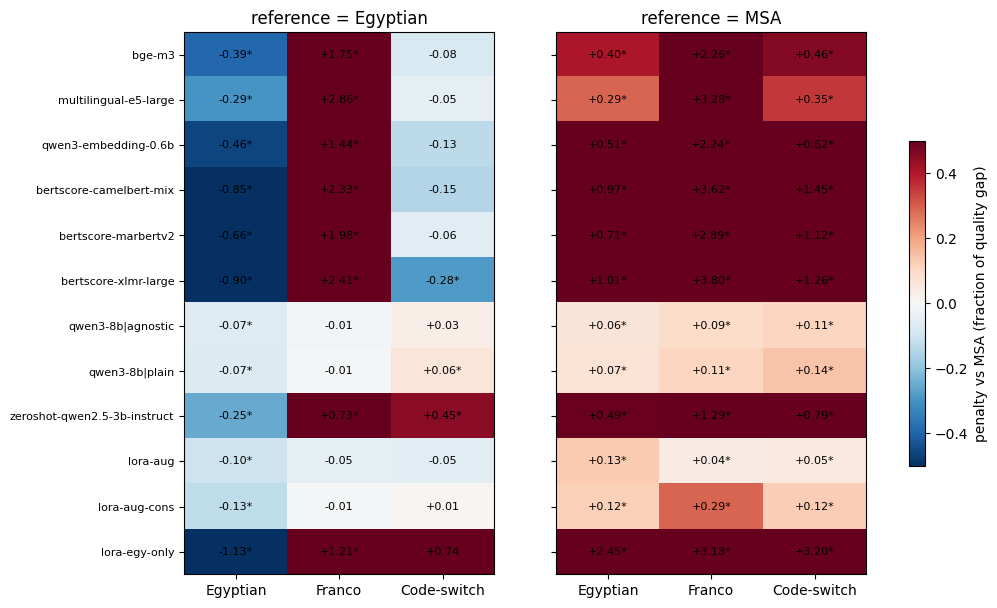

In [55]:
pw = C.pairwise_register_gaps(df)
pw.to_csv(C.RESULTS / "pairwise_register_gaps.csv", index=False)
vs = C.gaps_vs_msa(pw)
cols3 = ["egyptian", "franco", "codeswitch"]

fig, axes = plt.subplots(1, 2, figsize=(11, 0.42 * len(order) + 2), sharey=True)
for ax, rr in zip(axes, ["egyptian", "msa"]):
    sub = vs[vs.ref_register == rr]
    tab = sub.pivot(index="evaluator", columns="other", values="norm_gap").reindex(order)[cols3]
    pt = sub.pivot(index="evaluator", columns="other", values="p_holm").reindex(order)[cols3]
    im = ax.imshow(tab.values.astype(float), cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
    ax.set_xticks(range(3)); ax.set_xticklabels([C.REG_LABEL[c] for c in cols3])
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
    for i in range(len(order)):
        for j in range(3):
            v, p = tab.values[i, j], pt.values[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:+.2f}{'*' if p < 0.05 else ''}", ha="center", va="center", fontsize=8)
    ax.set_title(f"reference = {C.REG_LABEL[rr]}")
fig.colorbar(im, ax=axes, shrink=0.6, label="penalty vs MSA (fraction of quality gap)")
fig.savefig(C.FIGS / "fig1_register_gap_vs_msa.png", dpi=200, bbox_inches="tight")
plt.show()

## 3) Figure 2 — flip matrices (Egyptian reference)

Rows: the register of a **correct** answer. Columns: the register of an **incorrect** answer to the same question. Each cell is the fraction of questions where the correct answer scores **below** the incorrect one (0.5 = tie). A fair judge is dark-free everywhere; a bright row (e.g. Franco) means correct answers written in that register lose to wrong answers.

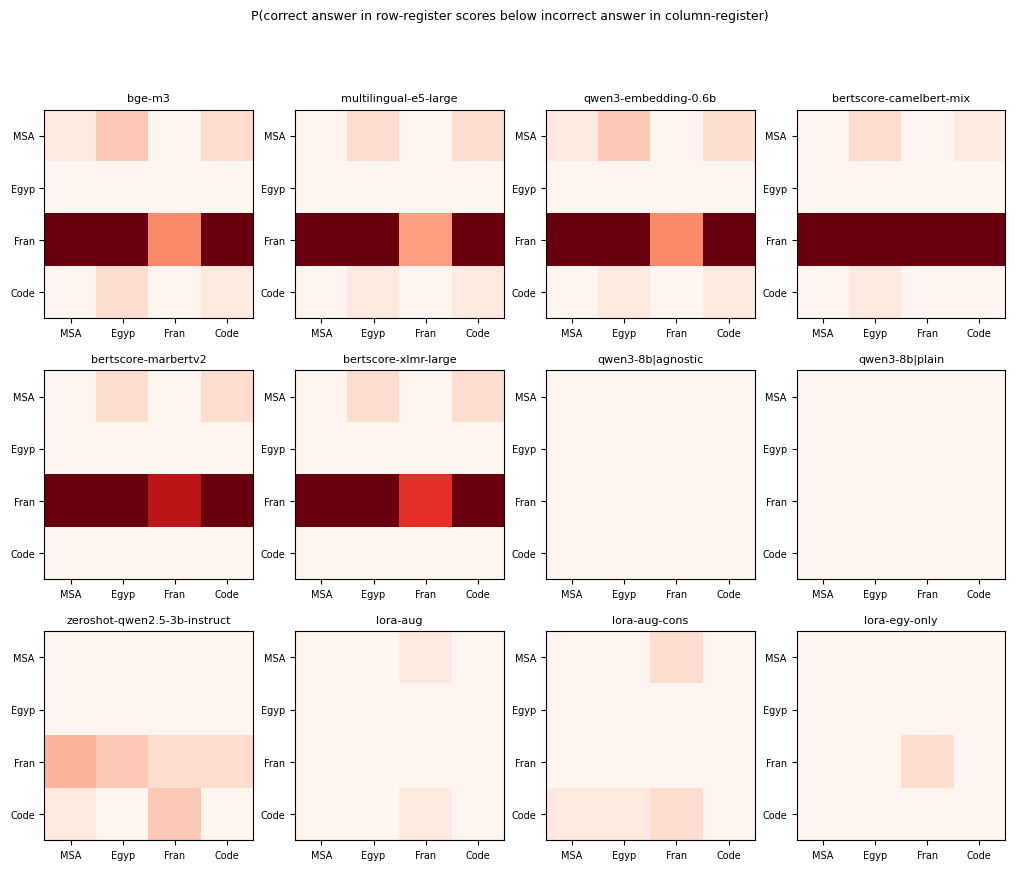

In [56]:
ncol = 4
nrow = int(np.ceil(len(order) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.1 * ncol, 3.2 * nrow), squeeze=False)
short = [C.REG_LABEL[r][:4] for r in C.REGISTERS]
for ax, ev in zip(axes.ravel(), order):
    m = C.flip_matrix(df, ev, "egyptian")
    ax.imshow(m.values.astype(float), vmin=0, vmax=0.5, cmap="Reds")
    ax.set_xticks(range(4)); ax.set_xticklabels(short, fontsize=7)
    ax.set_yticks(range(4)); ax.set_yticklabels(short, fontsize=7)
    ax.set_title(ev, fontsize=8)
for ax in axes.ravel()[len(order):]:
    ax.axis("off")
fig.suptitle("P(correct answer in row-register scores below incorrect answer in column-register)", fontsize=9)
fig.savefig(C.FIGS / "fig2_flip_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

## 4) Figure 3 — validity inside each register

Spearman correlation with the ground truth computed **within** each register (90 answers each). A judge that is accurate on MSA but drops on Franco is unfair even when its *average* gap looks small.

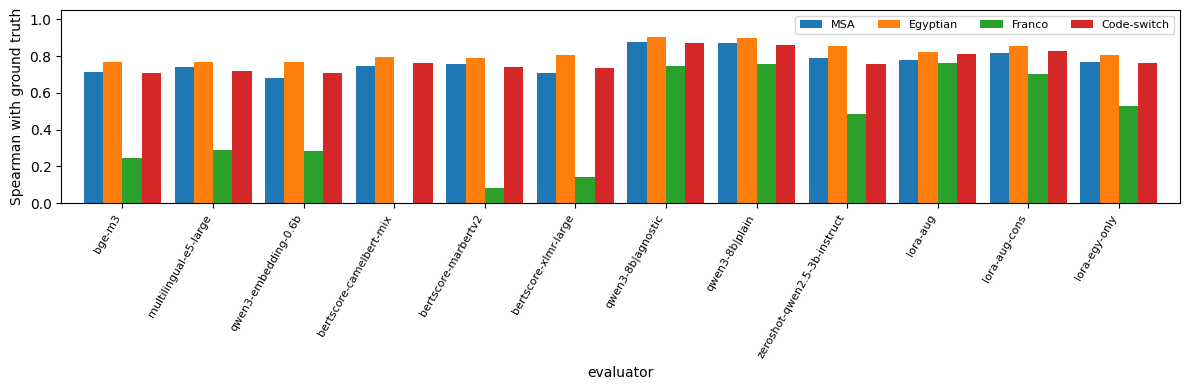

In [57]:
val = C.validity_table(df)
val.to_csv(C.RESULTS / "validity_by_register.csv", index=False)
v = val[val.ref_register == "egyptian"].set_index("evaluator").reindex(order)
ax = v[[f"spearman_{r}" for r in C.REGISTERS]].rename(columns=lambda c: C.REG_LABEL[c.replace("spearman_", "")]) \
      .plot.bar(figsize=(12, 4), width=0.85)
ax.set_ylabel("Spearman with ground truth"); ax.set_ylim(0, 1.05); ax.legend(ncol=4, fontsize=8)
plt.xticks(rotation=60, ha="right", fontsize=8); plt.tight_layout()
plt.savefig(C.FIGS / "fig3_validity_by_register.png", dpi=200, bbox_inches="tight")
plt.show()

## 5) Automatic findings (copy into the report after checking the figures)

A gap is reported only if it is **statistically significant** (Holm p < 0.05) **and practically relevant** (at least `MIN_EFFECT` = 5% of the evaluator's correct-vs-incorrect gap). With n = 30 and low-noise evaluators, tiny differences can be significant without mattering.

In [58]:
MIN_EFFECT = 0.05
no_sep = summ[summ.quality_gap <= 0][["evaluator", "ref_register"]].drop_duplicates()
if len(no_sep):
    print("Excluded (do NOT rank correct above incorrect, so their bias cannot be interpreted):",
          ", ".join(sorted(set(no_sep.evaluator))))
    print()
sig = vs[(vs.p_holm < 0.05) & (vs.norm_gap >= MIN_EFFECT)].sort_values("norm_gap", ascending=False)
rev = vs[(vs.p_holm < 0.05) & (vs.norm_gap <= -MIN_EFFECT)].sort_values("norm_gap")
if sig.empty and rev.empty:
    print("No evaluator shows a significant and practically relevant register gap relative to MSA.")
for r in sig.itertuples():
    print(f"- {r.evaluator} [ref={r.ref_register}]: MSA scores higher than {C.REG_LABEL[r.other]} by {r.gap:.3f} "
          f"(95% CI {r.ci_lo:.3f} to {r.ci_hi:.3f}) = {100 * r.norm_gap:.0f}% of its correct-vs-incorrect gap; p_holm = {r.p_holm:.3g}")
for r in rev.itertuples():
    print(f"- (reverse) {r.evaluator} [ref={r.ref_register}]: {C.REG_LABEL[r.other]} scores HIGHER than MSA by {-r.gap:.3f} "
          f"= {-100 * r.norm_gap:.0f}% of its gap; p_holm = {r.p_holm:.3g}")

- bertscore-xlmr-large [ref=msa]: MSA scores higher than Franco by 0.208 (95% CI 0.203 to 0.213) = 380% of its correct-vs-incorrect gap; p_holm = 1.12e-08
- bertscore-camelbert-mix [ref=msa]: MSA scores higher than Franco by 0.396 (95% CI 0.385 to 0.407) = 362% of its correct-vs-incorrect gap; p_holm = 1.12e-08
- multilingual-e5-large [ref=msa]: MSA scores higher than Franco by 0.194 (95% CI 0.185 to 0.202) = 328% of its correct-vs-incorrect gap; p_holm = 1.12e-08
- lora-egy-only [ref=msa]: MSA scores higher than Code-switch by 3.995 (95% CI 3.987 to 3.999) = 320% of its correct-vs-incorrect gap; p_holm = 1.12e-08
- lora-egy-only [ref=msa]: MSA scores higher than Franco by 3.963 (95% CI 3.890 to 4.000) = 318% of its correct-vs-incorrect gap; p_holm = 1.12e-08
- bertscore-marbertv2 [ref=msa]: MSA scores higher than Franco by 0.676 (95% CI 0.661 to 0.689) = 289% of its correct-vs-incorrect gap; p_holm = 1.12e-08
- multilingual-e5-large [ref=egyptian]: MSA scores higher than Franco by 0.1

## 6) Does the proposed judge help?

Compare the LoRA judges (family `lora`) with the untuned base model and with the two LLM-judge baselines. What we hope to see for the research question: **lower** `max_penalty_vs_msa_norm`, `inconsistency_norm` and `flip_cross_register`, with `spearman_all` **not** lower.

In [59]:
cmp = summ[summ.family.isin(["llm", "lora"]) & (summ.ref_register == "egyptian")]
cmp[["evaluator", "family", "max_penalty_vs_msa_norm", "inconsistency_norm", "flip_cross_register", "spearman_all"]].round(3)

,evaluator,family,max_penalty_vs_msa_norm,inconsistency_norm,flip_cross_register,spearman_all
12,qwen3-8b|agnostic,llm,0.034,0.069,0.000,0.848
14,qwen3-8b|plain,llm,0.060,0.077,0.000,0.843
16,zeroshot-qwen2.5-3b-instruct,llm,0.728,0.524,0.036,0.719
18,lora-aug,lora,-0.051,0.078,0.006,0.783
20,lora-aug-cons,lora,0.009,0.135,0.017,0.802
22,lora-egy-only,lora,1.206,1.229,0.000,0.730


In [60]:
backup()

backup saved to Google Drive: /content/drive/MyDrive/register_bias_backup


# Done
Results are in the `results/` folder (and in your Drive backup): `bias_summary.csv`, `pairwise_register_gaps.csv`, `results/figures/`, and the score files `scores_*.csv`.